# Top-down multiyear backtest of IFRS 9 ECL — residential mortgages

Self-contained implementation of the method on the companion A3 page (`ecl_backtest_A3_overview.html`): the ECL booked
at a reporting date *t₀* is compared, loan by loan, with the loss later realised on exactly those loans. Everything —
synthetic data, ECL engine, backtest — runs in this one notebook; nothing is read from or written to disk.

| Part | Content | A3 panel |
|---|---|---|
| A | Synthetic world (realised macro path with a 2023 stress), bank ECL engine with three scenarios, loan simulation 2015–2029, snapshots 31 Dec 2021 … 2026. Two miscalibrations are planted and documented. | — |
| B1–B3 | Freeze static cohorts, build the two test populations, measure the realised loss per loan (write-off shown to be unusable). | A, B steps 1–4 |
| B4 | **Truncation test** — EL(h) = Σ m₁…m_h vs RL(h); survivors excluded on both sides. | A left, step 5 |
| B5 | **Roll-forward test** — lifetime ECL(t₀) vs RL(h) + PV of the shadow lifetime ECL still held on survivors at t_h. | A right, step 6 |
| B6 | Hindsight ECL — same engine, realised macro path; both tests on the hindsight basis. | step 7 |
| B7 | Every combination: stage at t₀ × end state at t_h → EL and RL per cell, both tests; cells sum to the totals. | D |
| B8–B9 | Cohort × horizon triangles; traffic lights on the scenario band. | steps 8–9 |
| B10 | **Paired t-test** per cell, both tests, booked and hindsight basis. | E, step 10 |
| B11–B13 | Data checks; verification against the planted truth; committee summary. | step 11 |

Only `pandas`, `numpy`, `matplotlib`, `scipy`. Fixed seed; runs top to bottom. Conventions: reference dates *t₀* = 31 Dec 2021 … 2025,
development year *h* = calendar year *t₀ + h*, observation cut-off 31 Dec 2026, end-of-year timing, discounting at the loan EIR
frozen at *t₀*, *DF(h) = (1+r)^{−h}*. The test works at ECL level only: no PD / LGD / EAD component analysis and no overlays.

In [1]:
import warnings, textwrap
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy import stats

warnings.filterwarnings("ignore")
SEED = 20261102
np.random.seed(SEED)
pd.set_option("display.width", 170, "display.max_columns", 40, "display.float_format", lambda x: f"{x:,.3f}")

COHORT_COLORS = {2021: "#2a78d6", 2022: "#eb6834", 2023: "#1baf7a", 2024: "#eda100", 2025: "#e87ba4"}
STATUS_COLORS = {"GREEN": "#0ca30c", "AMBER": "#fab219", "RED": "#d03b3b", "n/a": "#f0efec"}
DIVERGING = LinearSegmentedColormap.from_list("ratio", ["#2a78d6", "#f0efec", "#e34948"])
mpl.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9.5, "legend.frameon": False})
EUR = lambda x: f"€{x/1e6:,.2f}m"
print("pandas", pd.__version__, "| numpy", np.__version__, "| matplotlib", mpl.__version__)

pandas 3.0.5 | numpy 2.5.3 | matplotlib 3.11.2


## Part A — Synthetic world and bank ECL engine (all in this notebook)

**A1 — Parameters.** Calendar, the realised macro path (unemployment and house prices, with the 2023 stress), the bank's
scenario sets at each 31 December (base / upside / downside with weights), and the parameters of *reality* (`TRUE`) versus the
*bank's engine* (`MODEL`). The two differ on purpose (see "Embedded truth" below).

In [2]:
# ----------------------------------------------------------------------------
# Calendar
# ----------------------------------------------------------------------------
ORIG_YEARS = (2015, 2021)          # originations spread over 2015..2021
SNAPSHOT_YEARS = list(range(2021, 2027))   # 31 Dec 2021 .. 31 Dec 2026 (observable)
LAST_OBS_YEAR = 2026
SIM_END_YEAR = 2029                # simulate truth beyond the observable window (oracle only)
REF_DATES = list(range(2021, 2026))        # cohorts t0 = 2021..2025
MAX_LIFE = 30                      # years of term structure kept by the engine
SCENARIOS = ["base", "upside", "downside"]

# ----------------------------------------------------------------------------
# Realised macro path (what actually happened). 2023 is the stress year.
# UR in %, HPI growth in % y/y.
# ----------------------------------------------------------------------------
REALISED_MACRO = pd.DataFrame({
    "year":    [2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026, 2027, 2028, 2029],
    "ur":      [5.8,  5.4,  5.0,  4.6,  4.2,  3.9,  5.6,  4.8,  4.4,  7.6,  6.1,  5.0,  4.4,  4.3,  4.3,  4.3],
    "hpi_yoy": [2.0,  2.0,  3.0,  2.0,  1.0,  1.0,  2.0,  6.0,  3.0, -12.0, -3.0,  3.0,  4.0,  3.0,  3.0,  3.0],
})
REALISED_MACRO["hpi_index"] = 100.0 * np.cumprod(1 + REALISED_MACRO["hpi_yoy"] / 100.0)
REALISED_MACRO["hpi_index"] /= REALISED_MACRO.loc[REALISED_MACRO.year == 2021, "hpi_index"].values[0] / 100.0
REALISED_MACRO = REALISED_MACRO.set_index("year")

# Long-run values used beyond the explicit forecast horizon (all scenarios).
LR_UR, LR_HPI = 4.5, 3.0

# ----------------------------------------------------------------------------
# Bank scenario sets at each reference date: UR path and HPI growth path for
# development years 1..5, and the probability weights. These are what the bank
# *believed* at each 31 December.
# ----------------------------------------------------------------------------
SCENARIO_SETS = {
    2021: {"weights": {"base": 0.55, "upside": 0.15, "downside": 0.30},
           "base":     {"ur": [4.5, 4.3, 4.2, 4.2, 4.2], "hpi": [3, 3, 3, 3, 3]},
           "upside":   {"ur": [3.8, 3.6, 3.6, 3.6, 3.6], "hpi": [6, 5, 4, 3, 3]},
           "downside": {"ur": [6.0, 7.0, 6.5, 5.5, 5.0], "hpi": [-5, -10, -3, 1, 2]}},
    2022: {"weights": {"base": 0.50, "upside": 0.15, "downside": 0.35},
           "base":     {"ur": [5.2, 5.0, 4.7, 4.5, 4.5], "hpi": [0, 2, 3, 3, 3]},
           "upside":   {"ur": [4.2, 4.0, 4.0, 4.0, 4.0], "hpi": [4, 4, 3, 3, 3]},
           "downside": {"ur": [7.5, 7.0, 6.0, 5.3, 5.0], "hpi": [-12, -5, 0, 2, 3]}},
    2023: {"weights": {"base": 0.50, "upside": 0.20, "downside": 0.30},
           "base":     {"ur": [6.5, 5.8, 5.2, 4.8, 4.6], "hpi": [-4, 0, 2, 3, 3]},
           "upside":   {"ur": [5.5, 4.8, 4.5, 4.3, 4.3], "hpi": [1, 3, 3, 3, 3]},
           "downside": {"ur": [8.5, 8.0, 7.0, 6.0, 5.5], "hpi": [-10, -6, -2, 1, 2]}},
    2024: {"weights": {"base": 0.55, "upside": 0.20, "downside": 0.25},
           "base":     {"ur": [5.5, 5.0, 4.7, 4.5, 4.5], "hpi": [2, 3, 3, 3, 3]},
           "upside":   {"ur": [4.6, 4.3, 4.2, 4.2, 4.2], "hpi": [5, 4, 3, 3, 3]},
           "downside": {"ur": [7.5, 7.0, 6.0, 5.3, 5.0], "hpi": [-8, -4, 0, 2, 3]}},
    2025: {"weights": {"base": 0.55, "upside": 0.20, "downside": 0.25},
           "base":     {"ur": [4.8, 4.6, 4.5, 4.5, 4.5], "hpi": [3, 3, 3, 3, 3]},
           "upside":   {"ur": [4.0, 3.8, 3.8, 3.8, 3.8], "hpi": [5, 4, 3, 3, 3]},
           "downside": {"ur": [7.0, 6.8, 6.0, 5.3, 5.0], "hpi": [-8, -5, 0, 2, 3]}},
    2026: {"weights": {"base": 0.55, "upside": 0.20, "downside": 0.25},
           "base":     {"ur": [4.5, 4.5, 4.5, 4.5, 4.5], "hpi": [3, 3, 3, 3, 3]},
           "upside":   {"ur": [3.9, 3.8, 3.8, 3.8, 3.8], "hpi": [5, 4, 3, 3, 3]},
           "downside": {"ur": [7.0, 6.8, 6.0, 5.3, 5.0], "hpi": [-8, -5, 0, 2, 3]}},
}

# ----------------------------------------------------------------------------
# Parameters: TRUE (reality) vs MODEL (bank engine)
# ----------------------------------------------------------------------------
TRUE = dict(
    pd_intercept=-5.00,       # logit of ~0.67 % for an average OO borrower, LTV 70, UR 4.5
    b_score=-0.55,            # per 1 sd of borrower score (higher score = safer)
    b_ltv=0.22,               # per 10 pp of indexed LTV above 70 %
    b_ur=0.32,                # per 1 pp of unemployment above 4.5 %
    btl_mult=1.50,            # BTL default-odds multiplier
    cured_mult=1.80,          # re-default risk after cure
    watch_mult=3.0,           # early-arrears ("watch") flag multiplies next-year default odds
    watch_a=0.03, watch_b=3.0,  # P(flag) = clip(a + b x core PD, 0, 0.5): flags are enriched in risky loans
    cpr=0.06,                 # annual prepayment rate
    cure_rate=0.30,           # cure probability in the year after default
    cure_cost=0.01,           # cost of a cure, share of EAD
    ead_uplift=1.025,         # arrears/interest capitalised at default
    haircut_base=0.20,        # forced-sale haircut in a flat market
    haircut_hpi_beta=0.50,    # extra haircut per unit of (negative) HPI y/y in the sale year
    hpi_passthrough_down=1.0, # full pass-through of price falls to achievable price
    sale_cost=0.06,           # workout cost, share of EAD
    lag_probs={1: 0.35, 2: 0.40, 3: 0.25},
    pwo_prob=0.15,            # probability of a post-write-off recovery
    pwo_share=0.03,           # its size, share of EAD, one year after liquidation
)

MODEL = dict(TRUE)
MODEL.update(
    btl_pd_scale=0.80,        # M1: BTL PD understated by 20 %
    hpi_passthrough_down=0.5, # M2a: only half of projected HPI falls hit collateral value
    haircut_hpi_beta=0.0,     # M2b: constant haircut, no widening in falling markets
    ead_uplift=1.02,          # minor: EAD uplift slightly below reality
    workout_lag=2,            # expected years from default to cash
    lgl_floor=0.02,
)

EMBEDDED_MISCALIBRATIONS = {
    "M1": {"component": "PD", "segment": "BTL",
           "description": "Model PD = 0.80 x true PD for buy-to-let loans at every horizon "
                          "(BTL odds multiplier calibrated on a benign sample).",
           "expected_signature": "Realised/expected ratio ~1.25 for BTL vs ~1.0 for owner-occupier "
                                 "in the hindsight (macro-corrected) view; positive 'default count vs PD' bar."},
    "M2": {"component": "LGD", "segment": "all, high LTV most exposed",
           "description": "Collateral model passes through only 50 % of projected HPI declines and "
                          "keeps a constant 20 % forced-sale haircut; reality: 100 % pass-through and "
                          "haircut = 20 % + 0.50 x |HPI fall| in the sale year.",
           "expected_signature": "Realised LGD >> modelled LGD on defaults liquidated in 2023-2024; "
                                 "positive 'realised vs modelled LGD' bar concentrated on the 2023 diagonal; "
                                 "benign years roughly unbiased."},
}

**A2 — The bank's ECL engine.** For every performing loan the engine produces, per scenario, the expected loss for each
future development year, `m[i, k] = S·PD·EAD·LGD·DF` (behavioural survival × marginal PD × exposure × LGD × discount factor),
with `m[i,1]` = 12-month ECL and `Σ_k m[i,k]` = lifetime ECL; for defaulted loans ECL = EAD × in-default LGD.
The engine itself is a black box for the backtest — only its outputs are used.

In [3]:
# ----------------------------------------------------------------------------
# Helpers
# ----------------------------------------------------------------------------
def _logit(p):
    return np.log(p / (1 - p))


def _sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


def seasoning(age):
    """Default-risk seasoning hump: peaks around year 3, decays after."""
    age = np.asarray(age, dtype=float)
    return 0.70 + 0.60 * np.exp(-0.5 * ((age - 3.0) / 2.5) ** 2)


def scheduled_balance(orig_balance, rate, term, k):
    """Annuity balance after k whole years (vectorised; k may be an array)."""
    k = np.asarray(k, dtype=float)
    g = (1 + rate)
    bal = orig_balance * (g ** term - g ** k) / (g ** term - 1)
    return np.clip(bal, 0.0, None)


def pd12_core(params, score_z, ltv_idx, age, ur, btl, cured):
    """Shared PD functional form (used by both reality and the bank model)."""
    x = (params["pd_intercept"]
         + params["b_score"] * score_z
         + params["b_ltv"] * (ltv_idx - 0.70) / 0.10
         + params["b_ur"] * (ur - 4.5)
         + np.log(seasoning(age))
         + np.log(params["btl_mult"]) * btl
         + np.log(params["cured_mult"]) * cured)
    return np.clip(_sigmoid(x), 1e-5, 0.95)


def watch_prob(params, pd_core):
    """Probability that a performing loan carries the early-arrears flag at year end."""
    return np.clip(params["watch_a"] + params["watch_b"] * pd_core, 0.0, 0.5)


def macro_path_from_scenario(t0, scenario, H=MAX_LIFE):
    """UR[h] and HPI growth[h] for h = 1..H under a scenario at t0 (long-run beyond year 5)."""
    s = SCENARIO_SETS[t0][scenario]
    ur = np.full(H, LR_UR)
    hpi = np.full(H, LR_HPI)
    ur[:5] = s["ur"]
    hpi[:5] = s["hpi"]
    return ur, hpi


def macro_path_realised(t0, H=MAX_LIFE):
    """Realised UR and HPI growth for development years 1..H after t0 (long-run after 2029)."""
    ur = np.full(H, LR_UR)
    hpi = np.full(H, LR_HPI)
    for h in range(1, H + 1):
        y = t0 + h
        if y in REALISED_MACRO.index:
            ur[h - 1] = REALISED_MACRO.loc[y, "ur"]
            hpi[h - 1] = REALISED_MACRO.loc[y, "hpi_yoy"]
    return ur, hpi


# ----------------------------------------------------------------------------
# The bank's ECL engine
# ----------------------------------------------------------------------------
class BankModel:
    """IFRS 9 ECL engine. Produces per-loan marginal expected-loss term structures.

    The engine is the same object at every reference date (no recalibration in
    the window), which is what makes a multi-cohort backtest interpretable.
    """

    def __init__(self, params=None):
        self.p = dict(MODEL if params is None else params)

    # -- PD ------------------------------------------------------------------
    def pd12(self, score_z, ltv_idx, age, ur, btl, cured, watch=None):
        """12-month PD. `watch` = observed early-arrears flag (year 1); None = use the expectation
        over the flag, which is what the engine does for development years >= 2."""
        p = self.p
        core = pd12_core(p, score_z, ltv_idx, age, ur, btl, cured)
        if watch is None:
            mult = 1.0 + (p["watch_mult"] - 1.0) * watch_prob(p, core)
        else:
            mult = np.where(watch == 1, p["watch_mult"], 1.0)
        pd_ = np.clip(core * mult, 1e-5, 0.95)
        return pd_ * np.where(btl == 1, p["btl_pd_scale"], 1.0)   # <-- M1

    # -- LGD -----------------------------------------------------------------
    def lgl(self, value_at_default, ead, hpi_change_to_sale):
        """Loss given liquidation as share of EAD.

        value_at_default   : indexed collateral value at the (projected) default date
        hpi_change_to_sale : projected cumulative HPI change between default and sale
        """
        p = self.p
        passthrough = np.where(hpi_change_to_sale < 0, p["hpi_passthrough_down"], 1.0)   # <-- M2a
        value_at_sale = value_at_default * (1 + passthrough * hpi_change_to_sale)
        haircut = p["haircut_base"]                                                     # <-- M2b (constant)
        proceeds = value_at_sale * (1 - haircut) - p["sale_cost"] * ead
        proceeds = np.clip(proceeds, 0.0, ead)
        safe_ead = np.where(ead > 0, ead, 1.0)
        return np.clip(1.0 - proceeds / safe_ead, p["lgl_floor"], 1.0), proceeds

    def lgd_from_lgl(self, lgl):
        p = self.p
        return (1 - p["cure_rate"]) * lgl + p["cure_rate"] * p["cure_cost"]

    # -- term structure --------------------------------------------------------
    def term_structure(self, cohort: pd.DataFrame, ur_path, hpi_path, t0: int,
                       H: int = MAX_LIFE, return_components: bool = False):
        """Marginal expected loss m[i, h] for h = 1..H for performing loans.

        cohort columns required: orig_balance, eir, term, age, orig_value, orig_year,
        score_z, product_btl, cured_flag, hpi_at_orig (index level).
        ur_path / hpi_path: arrays of length H (dev years 1..H) of UR (%) and HPI growth (%).
        """
        n = len(cohort)
        h = np.arange(1, H + 1)
        ob = cohort["orig_balance"].to_numpy()[:, None]
        r = cohort["eir"].to_numpy()[:, None]
        term = cohort["term"].to_numpy()[:, None]
        age0 = cohort["age"].to_numpy()[:, None]
        ov = cohort["orig_value"].to_numpy()[:, None]
        hpi_orig = cohort["hpi_at_orig"].to_numpy()[:, None]
        z = cohort["score_z"].to_numpy()[:, None]
        btl = cohort["product_btl"].to_numpy()[:, None]
        cured = cohort["cured_flag"].to_numpy()[:, None]
        watch = cohort["watch_flag"].to_numpy()[:, None]

        hpi_t0 = REALISED_MACRO.loc[t0, "hpi_index"]
        growth = np.asarray(hpi_path, dtype=float) / 100.0
        hpi_cum = hpi_t0 * np.cumprod(1 + growth)                    # index at end of dev year h
        hpi_start = np.concatenate([[hpi_t0], hpi_cum[:-1]])         # index at start of dev year h
        ur = np.asarray(ur_path, dtype=float)[None, :]

        age_h = age0 + h[None, :] - 1                                # age at start of dev year h
        bal_start = scheduled_balance(ob, r, term, age_h)            # balance at start of dev year h
        value_start = ov * hpi_start[None, :] / hpi_orig             # indexed collateral at start of h
        ltv = np.where(value_start > 0, bal_start / value_start, 0.0)
        pd_h = self.pd12(z, ltv, age_h, ur, btl, cured)              # expectation over the flag ...
        pd_h[:, :1] = self.pd12(z, ltv[:, :1], age_h[:, :1], ur[:, :1], btl, cured, watch=watch)  # ... except year 1
        pd_h = np.where(h[None, :] <= (term - age0), pd_h, 0.0)      # nothing beyond maturity

        ead_h = bal_start * self.p["ead_uplift"]
        # LGD: sale assumed `workout_lag` years after default
        lag = self.p["workout_lag"]
        idx_sale = np.minimum(np.arange(H) + lag, H - 1)
        hpi_change_to_sale = hpi_cum[idx_sale] / hpi_start - 1.0
        lgl, proceeds = self.lgl(value_start, ead_h, hpi_change_to_sale[None, :])
        # discount recoveries from sale back to default at the EIR
        pv_proceeds = proceeds * (1 + r) ** (-lag)
        lgl = np.clip(1 - pv_proceeds / np.where(ead_h > 0, ead_h, 1.0), self.p["lgl_floor"], 1.0)
        lgd_h = self.lgd_from_lgl(lgl)

        cpr = self.p["cpr"]
        surv = np.cumprod(1 - pd_h - cpr, axis=1)
        surv_prev = np.concatenate([np.ones((n, 1)), surv[:, :-1]], axis=1)
        df = (1 + r) ** (-h[None, :])
        m = surv_prev * pd_h * ead_h * lgd_h * df
        if return_components:
            return dict(m=m, surv_prev=surv_prev, pd=pd_h, ead=ead_h, lgd=lgd_h, df=df, h=h)
        return m

    def stage3_ecl(self, defaulted: pd.DataFrame, ur_path, hpi_path, t0: int):
        """ECL for loans in default at t0: EAD x in-default LGD (scenario-dependent via HPI)."""
        p = self.p
        ead = defaulted["ead_model"].to_numpy()
        ov = defaulted["orig_value"].to_numpy()
        hpi_orig = defaulted["hpi_at_orig"].to_numpy()
        r = defaulted["eir"].to_numpy()
        yrs_in_default = (t0 - defaulted["default_year"].to_numpy())
        hpi_t0 = REALISED_MACRO.loc[t0, "hpi_index"]
        growth = np.asarray(hpi_path, dtype=float) / 100.0
        hpi_cum = hpi_t0 * np.cumprod(1 + growth)
        value_now = ov * hpi_t0 / hpi_orig
        # remaining time to sale: default + lag - t0, at least 1 year
        rem = np.clip(p["workout_lag"] - yrs_in_default, 1, None).astype(int)
        hpi_change = hpi_cum[rem - 1] / hpi_t0 - 1.0
        lgl, proceeds = self.lgl(value_now, ead, hpi_change)
        pv_proceeds = proceeds * (1 + r) ** (-rem)
        lgl = np.clip(1 - pv_proceeds / ead, p["lgl_floor"], 1.0)
        # cure is still possible only in the first year after default
        cure_possible = (yrs_in_default == 0)
        lgd = np.where(cure_possible, self.lgd_from_lgl(lgl), lgl)
        return ead * lgd, lgd

**A3 — Reality.** Loans are simulated year by year under the realised macro path: defaults, prepayments, a cure decision one
year after default, collateral sales with a workout lag, post-write-off recoveries. Year-end snapshots 2021–2026 are the
observable data; the engine is run on each of them (`run_engine`) to produce staging, 12-month / lifetime / scenario ECLs and
the term structure `m_{s}_h1 … h5`. The event register carries a policy-timed write-off year, purely to show later that it must not be used.

In [4]:
# ----------------------------------------------------------------------------
# Reality
# ----------------------------------------------------------------------------
class TrueWorld:
    def __init__(self, n_loans=20000, seed=20261102):
        self.n = n_loans
        self.seed = seed
        self.rng = np.random.default_rng(seed)
        self.p = TRUE

    # -- static loan book ------------------------------------------------------
    def make_loans(self) -> pd.DataFrame:
        rng, n = self.rng, self.n
        orig_year = rng.integers(ORIG_YEARS[0], ORIG_YEARS[1] + 1, n)
        orig_month = rng.integers(1, 13, n)
        term = rng.choice([20, 25, 30], size=n, p=[0.25, 0.45, 0.30])
        orig_balance = np.round(np.exp(rng.normal(np.log(230_000), 0.40, n)), -2)
        orig_balance = np.clip(orig_balance, 50_000, 1_200_000)
        orig_ltv = np.clip(rng.beta(5, 2.5, n) * 0.47 + 0.50, 0.40, 0.97)
        orig_value = orig_balance / orig_ltv
        eir = np.clip(rng.normal(0.034, 0.007, n), 0.015, 0.06)
        score = np.clip(rng.normal(640, 70, n), 400, 850).round()
        score_z = (score - 640) / 70
        region = rng.choice(["North", "Midlands", "South", "Capital"], size=n, p=[0.25, 0.25, 0.30, 0.20])
        product = rng.choice(["OO", "BTL"], size=n, p=[0.75, 0.25])
        hpi_at_orig = REALISED_MACRO.loc[orig_year, "hpi_index"].to_numpy()
        loans = pd.DataFrame({
            "loan_id": [f"L{i:06d}" for i in range(n)],
            "orig_year": orig_year,
            "orig_date": pd.to_datetime({"year": orig_year, "month": orig_month, "day": 15}),
            "term": term,
            "maturity_year": orig_year + term,
            "orig_balance": orig_balance,
            "orig_value": orig_value,
            "orig_ltv": orig_ltv,
            "eir": eir,
            "score": score,
            "score_z": score_z,
            "region": region,
            "product": product,
            "product_btl": (product == "BTL").astype(int),
            "hpi_at_orig": hpi_at_orig,
        })
        return loans

    # -- annual simulation -----------------------------------------------------
    def simulate(self, loans: pd.DataFrame, model: BankModel):
        """Simulate loan histories 2015..SIM_END_YEAR; record observable snapshots 2021..2026."""
        rng, p = self.rng, self.p
        n = len(loans)
        ob = loans["orig_balance"].to_numpy()
        r = loans["eir"].to_numpy()
        term = loans["term"].to_numpy()
        oy = loans["orig_year"].to_numpy()
        ov = loans["orig_value"].to_numpy()
        hpi_orig = loans["hpi_at_orig"].to_numpy()
        z = loans["score_z"].to_numpy()
        btl = loans["product_btl"].to_numpy()

        status = np.full(n, "N", dtype="<U1")      # N not yet originated, P performing, D default, X prepaid, L liquidated
        balance = np.zeros(n)
        cured_flag = np.zeros(n, dtype=int)
        probation = np.zeros(n, dtype=int)
        watch = np.zeros(n, dtype=int)
        default_year = np.full(n, -1)
        ead_default = np.zeros(n)
        liq_year = np.full(n, -1)
        cure_pending = np.zeros(n, dtype=bool)

        events = []           # default-event register (truth, incl. unobservable resolutions)
        snapshots = []        # observable year-end snapshots 2021..2026
        stage_prev = {}       # loan_id -> stage at previous snapshot (for stage history)
        pd_orig_model = np.zeros(n)

        for y in range(ORIG_YEARS[0], SIM_END_YEAR + 1):
            ur_y = REALISED_MACRO.loc[y, "ur"]
            hpi_y = REALISED_MACRO.loc[y, "hpi_index"]
            hpi_prev = REALISED_MACRO.loc[y - 1, "hpi_index"]
            g_y = REALISED_MACRO.loc[y, "hpi_yoy"] / 100.0

            # --- originations this year: born performing at 31 Dec y
            born = (oy == y)
            status[born] = "P"
            balance[born] = ob[born]
            # model PD at origination (used later for the SICR relative test)
            if born.any():
                pd_orig_model[born] = model.pd12(z[born], ob[born] / ov[born], 0, ur_y, btl[born], 0, watch=np.zeros(born.sum()))

            # --- performing loans alive at start of year y (originated before y)
            alive = (status == "P") & (oy < y)
            if alive.any():
                idx = np.where(alive)[0]
                age_start = y - 1 - oy[idx]
                value_start = ov[idx] * hpi_prev / hpi_orig[idx]
                ltv_idx = balance[idx] / value_start
                pd_true = pd12_core(p, z[idx], ltv_idx, age_start, ur_y, btl[idx], cured_flag[idx])
                pd_true = np.clip(pd_true * np.where(watch[idx] == 1, p["watch_mult"], 1.0), 1e-5, 0.95)
                u = rng.random(len(idx))
                d = u < pd_true
                x = (~d) & (u < pd_true + p["cpr"])
                s = ~(d | x)
                # defaults
                di = idx[d]
                status[di] = "D"
                default_year[di] = y
                ead_default[di] = balance[di] * p["ead_uplift"]
                cure_pending[di] = True
                balance[di] = ead_default[di]
                # prepayments
                xi = idx[x]
                status[xi] = "X"
                balance[xi] = 0.0
                # survivors amortise
                si = idx[s]
                balance[si] = scheduled_balance(ob[si], r[si], term[si], y - oy[si])
                probation[si] = np.maximum(probation[si] - 1, 0)
                # early-arrears / watch flag at year end: enriched in risky loans and raises next-year PD (x watch_mult)
                pd_next = pd12_core(p, z[si], balance[si] / (ov[si] * hpi_y / hpi_orig[si]),
                                    y - oy[si], ur_y, btl[si], cured_flag[si])
                watch[si] = (rng.random(len(si)) < watch_prob(p, pd_next)).astype(int)
                watch[di] = 0
                watch[xi] = 0

            # --- loans in default: cure decision one year after default, else liquidation
            ind = np.where((status == "D") & (default_year < y))[0]
            if len(ind):
                yrs = y - default_year[ind]
                # cure decision
                dec = ind[yrs == 1]
                if len(dec):
                    c = rng.random(len(dec)) < p["cure_rate"]
                    ci = dec[c]
                    status[ci] = "P"
                    cured_flag[ci] = 1
                    probation[ci] = 2
                    cure_pending[ci] = False
                    for i in ci:
                        events.append(dict(loan_id=loans.loan_id.iat[i], default_year=default_year[i],
                                           ead_default=ead_default[i], outcome="cure",
                                           cure_year=y, liq_year=np.nan, lag=np.nan,
                                           recovery_net=np.nan, recovery_year=np.nan,
                                           pwo_recovery=0.0, pwo_year=np.nan,
                                           resolution_year=y, cost=p["cure_cost"] * ead_default[i]))
                    default_year[ci] = -1
                    ead_default[ci] = 0.0
                    # the rest get a liquidation date
                    ni = dec[~c]
                    cure_pending[ni] = False
                    lags = rng.choice(list(p["lag_probs"].keys()), size=len(ni), p=list(p["lag_probs"].values()))
                    liq_year[ni] = default_year[ni] + lags
                # liquidations due this year
                liq = ind[(liq_year[ind] == y)]
                if len(liq):
                    value_sale = ov[liq] * hpi_y / hpi_orig[liq]
                    haircut = p["haircut_base"] + p["haircut_hpi_beta"] * np.maximum(0.0, -g_y)
                    proceeds = value_sale * (1 - haircut) - p["sale_cost"] * ead_default[liq]
                    proceeds = np.clip(proceeds, 0.0, ead_default[liq])
                    pwo = rng.random(len(liq)) < p["pwo_prob"]
                    for k, i in enumerate(liq):
                        events.append(dict(loan_id=loans.loan_id.iat[i], default_year=default_year[i],
                                           ead_default=ead_default[i], outcome="liquidation",
                                           cure_year=np.nan, liq_year=y, lag=y - default_year[i],
                                           recovery_net=proceeds[k], recovery_year=y,
                                           pwo_recovery=(p["pwo_share"] * ead_default[i] if pwo[k] else 0.0),
                                           pwo_year=(y + 1 if pwo[k] else np.nan),
                                           resolution_year=(y + 1 if pwo[k] else y),
                                           cost=p["sale_cost"] * ead_default[i]))
                    status[liq] = "L"
                    balance[liq] = 0.0

            # --- observable snapshot at 31 Dec y
            if y in SNAPSHOT_YEARS:
                onbook = np.where((status == "P") | (status == "D"))[0]
                snap = loans.iloc[onbook].copy()
                snap["snapshot_year"] = y
                snap["status"] = status[onbook]
                snap["age"] = y - oy[onbook]
                snap["balance"] = balance[onbook]
                snap["watch_flag"] = watch[onbook]
                snap["cured_flag"] = cured_flag[onbook]
                snap["probation"] = probation[onbook]
                snap["default_year"] = np.where(status[onbook] == "D", default_year[onbook], np.nan)
                snap["ead_model"] = np.where(status[onbook] == "D", ead_default[onbook],
                                             balance[onbook] * model.p["ead_uplift"])
                snap["ltv_indexed"] = balance[onbook] / (ov[onbook] * hpi_y / hpi_orig[onbook])
                snap["pd12_orig_model"] = pd_orig_model[onbook]
                snapshots.append(snap)

        snapshots = pd.concat(snapshots, ignore_index=True)
        events = pd.DataFrame(events)
        # loans still in default at the end of the simulation never resolve (not needed: SIM_END is long)
        return snapshots, events

    # ------------------------------------------------------------------------
def run_engine(snapshots: pd.DataFrame, model: BankModel) -> pd.DataFrame:
    """Apply the bank's ECL engine at every snapshot: staging, scenario ECLs, term structures."""
    out = []
    for y, snap in snapshots.groupby("snapshot_year", sort=True):
        snap = snap.copy()
        sc = SCENARIO_SETS[y]
        w = sc["weights"]
        perf = snap["status"].eq("P").to_numpy()
        dflt = ~perf
        n = len(snap)
        H5 = 5
        margs = {s: np.zeros((n, H5)) for s in SCENARIOS}
        ecl12 = {s: np.zeros(n) for s in SCENARIOS}
        ecllife = {s: np.zeros(n) for s in SCENARIOS}
        pd12 = {s: np.zeros(n) for s in SCENARIOS}
        lgd1 = {s: np.zeros(n) for s in SCENARIOS}
        for s in SCENARIOS:
            ur, hpi = macro_path_from_scenario(y, s)
            comp = model.term_structure(snap.loc[perf], ur, hpi, y, return_components=True)
            margs[s][perf] = comp["m"][:, :H5]
            ecl12[s][perf] = comp["m"][:, 0]
            ecllife[s][perf] = comp["m"].sum(axis=1)
            pd12[s][perf] = comp["pd"][:, 0]
            lgd1[s][perf] = comp["lgd"][:, 0]
            if dflt.any():
                e3, l3 = model.stage3_ecl(snap.loc[dflt], ur, hpi, y)
                margs[s][dflt, 0] = e3
                ecl12[s][dflt] = e3
                ecllife[s][dflt] = e3
                pd12[s][dflt] = 1.0
                lgd1[s][dflt] = l3
        # weighted
        for s in SCENARIOS:
            snap[f"pd12_{s}"] = pd12[s]
            snap[f"lgd1_{s}"] = lgd1[s]
            snap[f"ecl12_{s}"] = ecl12[s]
            snap[f"ecllife_{s}"] = ecllife[s]
            for h in range(1, H5 + 1):
                snap[f"m_{s}_h{h}"] = margs[s][:, h - 1]
        snap["pd12_w"] = sum(w[s] * pd12[s] for s in SCENARIOS)
        snap["lgd1_w"] = sum(w[s] * lgd1[s] for s in SCENARIOS)
        snap["ecl12_w"] = sum(w[s] * ecl12[s] for s in SCENARIOS)
        snap["ecllife_w"] = sum(w[s] * ecllife[s] for s in SCENARIOS)
        for h in range(1, H5 + 1):
            snap[f"m_w_h{h}"] = sum(w[s] * margs[s][:, h - 1] for s in SCENARIOS)
        for s in SCENARIOS:
            snap[f"w_{s}"] = w[s]

        # --- staging
        sicr = ((snap["pd12_base"] / snap["pd12_orig_model"].clip(lower=1e-6) > 2.5) & (snap["pd12_base"] > 0.004)) \
            | (snap["watch_flag"] == 1) | (snap["probation"] > 0)
        stage = np.where(dflt, 3, np.where(sicr, 2, 1))
        snap["stage"] = stage
        snap["ecl_booked_model"] = np.where(stage == 1, snap["ecl12_w"], snap["ecllife_w"])
        snap["ecl_shadow_life"] = snap["ecllife_w"]          # = booked for Stage 2/3, shadow for Stage 1
        snap["ecl_booked"] = snap["ecl_booked_model"]
        out.append(snap)
    return pd.concat(out, ignore_index=True)


def add_stage_history(snapshots: pd.DataFrame, events: pd.DataFrame) -> pd.DataFrame:
    """Attach to each default event the stage at the previous snapshot (if observable)."""
    key = snapshots.set_index(["loan_id", "snapshot_year"])["stage"]
    prev = pd.MultiIndex.from_arrays([events["loan_id"], events["default_year"] - 1])
    events = events.copy()
    events["stage_prev_snapshot"] = key.reindex(prev).to_numpy()
    return events


def finalise_events(events: pd.DataFrame, loans: pd.DataFrame) -> pd.DataFrame:
    """Observability flags and the oracle economic LGD (uses all cash flows, even post-2026)."""
    ev = events.merge(loans[["loan_id", "eir", "product", "region"]], on="loan_id", how="left")
    ev["resolved_by_last_obs"] = ev["resolution_year"] <= LAST_OBS_YEAR
    # observable fields: anything dated after the last observable year is masked
    for col in ["cure_year", "liq_year", "recovery_year", "pwo_year"]:
        ev[col + "_obs"] = np.where(ev[col] <= LAST_OBS_YEAR, ev[col], np.nan)
    ev["recovery_net_obs"] = np.where(ev["recovery_year"] <= LAST_OBS_YEAR, ev["recovery_net"], np.nan)
    ev["pwo_recovery_obs"] = np.where(ev["pwo_year"] <= LAST_OBS_YEAR, ev["pwo_recovery"], 0.0)
    ev["outcome_obs"] = np.where(ev["resolved_by_last_obs"], ev["outcome"],
                                 np.where(ev["liq_year_obs"].notna(), "liquidation", "unresolved"))
    # oracle economic LGD at the default date (all cash flows, discounted at EIR)
    r = ev["eir"].to_numpy()
    ead = ev["ead_default"].to_numpy()
    liq = ev["outcome"].eq("liquidation").to_numpy()
    dy = ev["default_year"].to_numpy().astype(float)
    rec = np.nan_to_num(ev["recovery_net"].to_numpy(dtype=float))
    ly = np.nan_to_num(ev["liq_year"].to_numpy(dtype=float), nan=0.0)
    pwo = np.nan_to_num(ev["pwo_recovery"].to_numpy(dtype=float))
    py = np.nan_to_num(ev["pwo_year"].to_numpy(dtype=float), nan=0.0)
    pv = np.where(liq, rec * (1 + r) ** -np.maximum(ly - dy, 0), 0.0)
    pv = pv + np.where(pwo > 0, pwo * (1 + r) ** -np.maximum(py - dy, 0), 0.0)
    lgd = 1 - pv / ead
    lgd[~liq] = TRUE["cure_cost"]
    ev["lgd_real_oracle"] = lgd
    # accounting write-off (never used by the test): the shortfall is written off in the year of the collateral sale,
    # undiscounted, and recoveries received after that are booked separately
    ev["writeoff_year"] = np.where(ev["outcome"].eq("liquidation"), ev["liq_year"], np.nan)
    ev["writeoff_amount"] = np.where(ev["outcome"].eq("liquidation"), ev["ead_default"] - ev["recovery_net"], 0.0)
    return ev

In [5]:
# ---- A4: generate -------------------------------------------------------------------------------
world = TrueWorld(n_loans=20000, seed=SEED)
model = BankModel()
loans = world.make_loans()
snap_raw, events = world.simulate(loans, model)
snap = run_engine(snap_raw, model)
events = finalise_events(add_stage_history(snap, events), loans)

macro_r = REALISED_MACRO.copy()
REF_DATES, LAST, SCEN = list(range(2021, 2026)), LAST_OBS_YEAR, list(SCENARIOS)

print(f"loans originated: {len(loans):,}   snapshot rows: {len(snap):,}   default events: {len(events):,}")
(snap.groupby("snapshot_year")
     .agg(loans=("loan_id", "size"), balance=("balance", "sum"),
          stage1=("stage", lambda s: (s == 1).mean()), stage2=("stage", lambda s: (s == 2).mean()), stage3=("stage", lambda s: (s == 3).mean()),
          ecl_booked=("ecl_booked", "sum"), shadow_lifetime=("ecl_shadow_life", "sum"), avg_pd12=("pd12_w", "mean"), avg_lgd=("lgd1_w", "mean"))
     .assign(coverage_bps=lambda d: 1e4 * d.ecl_booked / d.balance))

loans originated: 20,000   snapshot rows: 84,336   default events: 2,061


,loans,balance,stage1,stage2,stage3,ecl_booked,shadow_lifetime,avg_pd12,avg_lgd,coverage_bps
snapshot_year,,,,,,,,,,
2021,16732,"3,870,750,883.310",0.924,0.055,0.020,"8,909,496.259","20,019,313.905",0.032,0.065,23.017
2022,15554,"3,485,321,491.901",0.918,0.062,0.020,"9,705,354.013","17,947,820.181",0.036,0.059,27.846
2023,14477,"3,139,601,871.313",0.805,0.157,0.038,"28,654,183.023","39,104,713.481",0.065,0.085,91.267
2024,13506,"2,825,259,498.793",0.872,0.086,0.042,"20,357,523.715","25,636,283.723",0.059,0.069,72.055
2025,12508,"2,510,557,525.183",0.897,0.070,0.033,"11,268,391.406","14,726,090.039",0.044,0.059,44.884
2026,11559,"2,220,939,366.106",0.921,0.057,0.022,"5,256,335.004","7,668,098.006",0.031,0.052,23.667


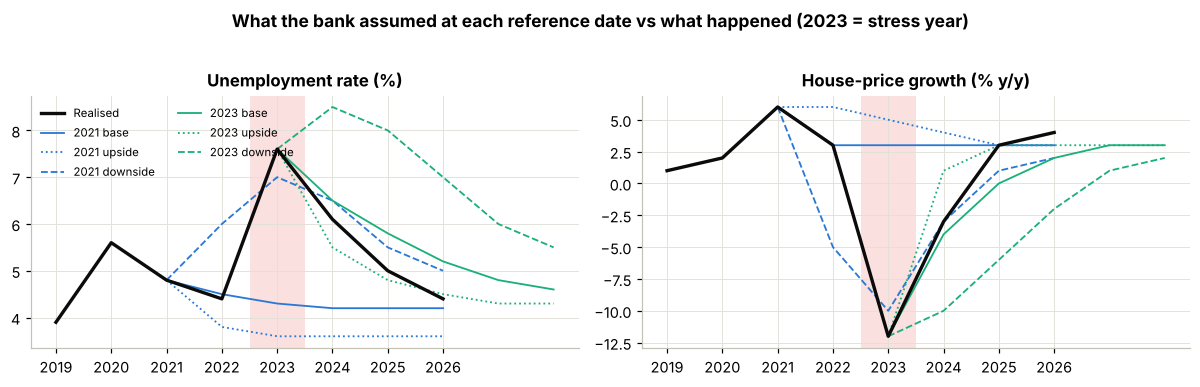

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
yrs = list(range(2019, 2027))
for ax, var, lab in zip(axes, ["ur", "hpi_yoy"], ["Unemployment rate (%)", "House-price growth (% y/y)"]):
    ax.plot(yrs, macro_r.loc[yrs, var], color="#0b0b0b", lw=2.2, label="Realised", zorder=5)
    for t0 in [2021, 2023]:
        for s, ls in zip(SCEN, ["-", ":", "--"]):
            sc = SCENARIO_SETS[t0][s]; key = "ur" if var == "ur" else "hpi"
            ax.plot([t0] + [t0 + h for h in range(1, 6)], [macro_r.loc[t0, var]] + sc[key], ls=ls, lw=1.2, color=COHORT_COLORS[t0], label=f"{t0} {s}")
    ax.axvspan(2022.5, 2023.5, color="#fae0de", zorder=0, lw=0); ax.set_title(lab); ax.set_xticks(yrs)
axes[0].legend(ncol=2, fontsize=7.5, loc="upper left")
plt.suptitle("What the bank assumed at each reference date vs what happened (2023 = stress year)", y=1.02, fontweight="bold")
plt.tight_layout(); plt.show()

### ⚠️ Embedded truth — for verification only, never an input to the backtest

The engine differs from reality in two planted ways (plus a minor EAD uplift). The top-down test works at ECL level: it should
detect that the engine is **biased** (and in which direction, for which cohorts) — it is not designed to say *which component*
is wrong, and this notebook does not try to. The final verification cell checks only the ECL-level claim.

In [7]:
for k, v in EMBEDDED_MISCALIBRATIONS.items():
    print(f"{k} [{v['component']} — segment: {v['segment']}]")
    print("   ", textwrap.fill(v["description"], 110, subsequent_indent="    "))
diff = {k: (TRUE.get(k), MODEL.get(k)) for k in set(TRUE) | set(MODEL) if TRUE.get(k) != MODEL.get(k)}
print("\nParameter differences TRUE vs MODEL:")
for k, (t, m) in sorted(diff.items()): print(f"   {k:22s} true={t}   model={m}")
print("\nECL-level expectation: realised losses above the engine's forecast even with the right macro path, for every cohort;"
      "\nstrongest where house prices fell between default and sale (2021–22 cohorts).")

M1 [PD — segment: BTL]
    Model PD = 0.80 x true PD for buy-to-let loans at every horizon (BTL odds multiplier calibrated on a benign
    sample).
M2 [LGD — segment: all, high LTV most exposed]
    Collateral model passes through only 50 % of projected HPI declines and keeps a constant 20 % forced-sale
    haircut; reality: 100 % pass-through and haircut = 20 % + 0.50 x |HPI fall| in the sale year.

Parameter differences TRUE vs MODEL:
   btl_pd_scale           true=None   model=0.8
   ead_uplift             true=1.025   model=1.02
   haircut_hpi_beta       true=0.5   model=0.0
   hpi_passthrough_down   true=1.0   model=0.5
   lgl_floor              true=None   model=0.02
   workout_lag            true=None   model=2

ECL-level expectation: realised losses above the engine's forecast even with the right macro path, for every cohort;
strongest where house prices fell between default and sale (2021–22 cohorts).


## Part B — The backtest

### B1 — Freeze one static cohort per reference date (step 2)
Every loan on book at 31 Dec *t₀* with its stage, EAD, EIR, booked ECL, upside / downside ECL and the expected loss per year
`m₁ … m₅` (plus the lifetime total). Nothing is restated later. Integrity: `m₁` = 12-month ECL, `Σ m ≤ lifetime`, Σ booked = provision.

In [8]:
H5 = 5
TS = {}       # per cohort: cumulative expected loss matrices [loan × h], one per scenario and weighted
cohorts = {}  # per cohort: (frozen frame, max horizon H)

for t0 in REF_DATES:
    c = snap[snap.snapshot_year == t0].set_index("loan_id").copy()
    H = LAST - t0
    ts = {f"cum_{s}": c[[f"m_{s}_h{h}" for h in range(1, H5 + 1)]].to_numpy().cumsum(axis=1) for s in SCEN + ["w"]}
    TS[t0] = ts; cohorts[t0] = (c, H)

chk = []
for t0, (c, H) in cohorts.items():
    m5 = TS[t0]["cum_w"][:, -1]
    chk.append(dict(t0=t0, loans=len(c), H=H, EAD=c.ead_model.sum(), booked_ECL=c.ecl_booked.sum(),
                    lifetime_shadow=c.ecl_shadow_life.sum(), lifetime_up=c.ecllife_upside.sum(), lifetime_down=c.ecllife_downside.sum(),
                    share_of_lifetime_in_5y=m5.sum() / c.ecllife_w.sum(),
                    m1_equals_12m=np.allclose(c.m_w_h1, c.ecl12_w), cum5_le_life=bool((m5 <= c.ecllife_w + 1e-6).all())))
pd.DataFrame(chk).set_index("t0")

,loans,H,EAD,booked_ECL,lifetime_shadow,lifetime_up,lifetime_down,share_of_lifetime_in_5y,m1_equals_12m,cum5_le_life
t0,,,,,,,,,,
2021,16732,5,"3,946,541,866.559","8,909,496.259","20,019,313.905","10,179,022.550","38,994,119.969",0.895,True,True
2022,15554,4,"3,553,500,238.370","9,705,354.013","17,947,820.181","9,488,277.492","29,823,777.240",0.911,True,True
2023,14477,3,"3,199,771,751.969","28,654,183.023","39,104,713.481","21,358,831.953","64,926,225.208",0.963,True,True
2024,13506,2,"2,879,154,538.916","20,357,523.715","25,636,283.723","17,519,054.049","42,046,472.684",0.957,True,True
2025,12508,1,"2,558,939,078.045","11,268,391.406","14,726,090.039","10,398,607.339","24,140,734.758",0.940,True,True


### B2 — Two test populations (step 3)
(a) **Stage 2 + 3** at their booked lifetime ECL (Stage 3: the whole ECL in year 1); (b) **whole book**, each Stage 1 loan's
12-month ECL replaced by its *shadow* lifetime term structure. For *h* = 1 the booked and shadow figures coincide (12-m ECL = m₁).

In [9]:
TESTS = {"Stage 2+3": lambda c: (c.stage >= 2).to_numpy(), "Whole book (shadow)": lambda c: np.ones(len(c), bool)}
rows = []
for t0, (c, H) in cohorts.items():
    for name, f in TESTS.items():
        m = f(c)
        rows.append(dict(t0=t0, population=name, loans=int(m.sum()), EAD=c.ead_model[m].sum(), booked_ECL=c.ecl_booked[m].sum(),
                         lifetime_ECL_tested=c.ecl_shadow_life[m].sum(), of_which_shadow_uplift=(c.ecllife_w - c.ecl12_w)[m & (c.stage == 1).to_numpy()].sum()))
pd.DataFrame(rows).set_index(["t0", "population"])

loans               EAD     booked_ECL  lifetime_ECL_tested  of_which_shadow_uplift
t0   population                                                                                              
2021 Stage 2+3             1266   297,860,679.095  6,034,848.029        6,034,848.029                   0.000
     Whole book (shadow)  16732 3,946,541,866.559  8,909,496.259       20,019,313.905          11,109,817.646
2022 Stage 2+3             1274   291,634,221.783  6,588,649.269        6,588,649.269                   0.000
     Whole book (shadow)  15554 3,553,500,238.370  9,705,354.013       17,947,820.181           8,242,466.167
2023 Stage 2+3             2817   654,254,506.006 23,261,413.804       23,261,413.804                   0.000
     Whole book (shadow)  14477 3,199,771,751.969 28,654,183.023       39,104,713.481          10,450,530.457
2024 Stage 2+3             1729   388,805,766.727 17,439,207.287       17,439,207.287                   0.000
     Whole book (shadow)  13506 2,879,154,538.916 20,357,523.715       25,636,283.723           5,278,760.008
2025 Stage 2+3             1292   277,950,643.221  9,713,292.816        9,713,292.816                   0.000
     Whole book (shadow)  12508 2,558,939,078.045 11,268,391.406       14,726,090.039           3,457,698.633

### B3 — Realised loss per loan (step 4)
For every cohort loan: first default after *t₀* in development year τ, EAD then, cash recoveries discounted to τ at the EIR →
realised LGD *L*; loss = (1+r)^{−τ} · EAD(τ) · L. Cure = workout cost only. Unresolved at the cut-off = cash so far + Stage 3
provision at 31 Dec 2026 as best estimate. Loans already in Stage 3 at *t₀* = EAD − PV(cash after *t₀*), booked at *h* = 1.
A loan that never defaults has realised loss 0. **Write-off dates are not used** — shown below only to demonstrate the lag.

In [10]:
s3_last = snap[(snap.snapshot_year == LAST) & (snap.status == "D")].set_index("loan_id")

def realised_lgd_obs(ev):
    r, ead, dy = ev.eir.to_numpy(), ev.ead_default.to_numpy(), ev.default_year.to_numpy()
    out = np.full(len(ev), np.nan)
    cure, liq, unres = (ev.outcome_obs.eq(k).to_numpy() for k in ["cure", "liquidation", "unresolved"])
    out[cure] = TRUE["cure_cost"]
    rec = np.nan_to_num(ev.recovery_net_obs.to_numpy(dtype=float)); ly = np.nan_to_num(ev.liq_year_obs.to_numpy(dtype=float), nan=0.0)
    pwo = np.nan_to_num(ev.pwo_recovery_obs.to_numpy(dtype=float)); py = np.nan_to_num(ev.pwo_year_obs.to_numpy(dtype=float), nan=0.0)
    pv = rec * (1 + r) ** -np.maximum(ly - dy, 0) + np.where(pwo > 0, pwo * (1 + r) ** -np.maximum(py - dy, 0), 0.0)
    out[liq] = 1 - pv[liq] / ead[liq]
    s3 = s3_last.reindex(ev.loan_id[unres]); lgd_now = (s3.ecl_booked / s3.ead_model).to_numpy()
    out[unres] = 1 - (1 - lgd_now) * (1 + r[unres]) ** -(LAST - dy[unres])
    return out

events["lgd_real"] = realised_lgd_obs(events)

def realised_losses(t0, c):
    ev = events[events.loan_id.isin(c.index)]
    perf_ids = c.index[c.status == "P"]
    inw = ev[(ev.default_year > t0) & (ev.default_year <= LAST) & ev.loan_id.isin(perf_ids)].sort_values("default_year").drop_duplicates("loan_id").copy()
    inw["tau"] = inw.default_year - t0
    inw["pv_loss_t0"] = (1 + inw.eir) ** -inw.tau * inw.ead_default * inw.lgd_real
    inw["stage_t0"] = c.loc[inw.loan_id, "stage"].to_numpy()
    op = ev[ev.loan_id.isin(c.index[c.status == "D"]) & (ev.default_year <= t0)]
    op = op[op[["cure_year", "liq_year"]].max(axis=1) > t0].sort_values("default_year").drop_duplicates("loan_id", keep="last").copy()
    op["tau"] = 1; op["stage_t0"] = 3
    fwd = (1 + op.eir) ** (t0 - op.default_year)
    op["pv_loss_t0"] = np.where(op.outcome_obs.eq("cure"), TRUE["cure_cost"] * op.ead_default, op.ead_default * (1 - (1 - op.lgd_real) * fwd))
    cols = ["loan_id", "default_year", "tau", "ead_default", "lgd_real", "pv_loss_t0", "outcome_obs", "resolved_by_last_obs", "stage_t0", "writeoff_year", "writeoff_amount", "eir"]
    return pd.concat([inw[cols], op[cols]], ignore_index=True)

RL = {t0: realised_losses(t0, c) for t0, (c, H) in cohorts.items()}

def rl_matrix(t0):
    # per-loan cumulative realised loss by horizon: [loan × h]
    c, H = cohorts[t0]; rl = RL[t0]
    M = np.zeros((len(c), H5)); idx = c.index.get_indexer(rl.loan_id)
    for k in range(H5):
        M[idx, k] += np.where(rl.tau.to_numpy() <= k + 1, rl.pv_loss_t0.to_numpy(), 0.0)
    return M
RLM = {t0: rl_matrix(t0) for t0 in REF_DATES}

tbl = pd.concat([r.assign(t0=t0) for t0, r in RL.items()])
(tbl.groupby(["t0", "tau"]).agg(defaults=("loan_id", "size"), EAD_at_default=("ead_default", "sum"), avg_L=("lgd_real", "mean"),
                                 pv_loss_t0=("pv_loss_t0", "sum"), unresolved_share=("resolved_by_last_obs", lambda s: 1 - s.mean()))
    .unstack("tau").round(3))

defaults                                  EAD_at_default                                                              avg_L                             pv_loss_t0  \
tau         1       2       3       4       5               1               2              3              4              5     1     2     3     4     5              1   
t0                                                                                                                                                                        
2021  512.000 414.000 317.000 176.000 102.000 123,950,482.857 100,212,578.522 71,967,155.067 37,497,647.262 21,990,104.071 0.117 0.103 0.083 0.073 0.056 13,433,806.115   
2022  727.000 321.000 178.000 102.000     NaN 177,096,622.788  72,448,750.604 37,716,003.488 21,990,104.071            NaN 0.128 0.083 0.072 0.056   NaN 21,201,036.727   
2023  870.000 178.000 102.000     NaN     NaN 205,582,184.184  37,716,003.488 21,990,104.071            NaN            NaN 0.106 0.072 0.056   NaN   NaN 21,021,021.138   
2024  750.000 111.000     NaN     NaN     NaN 170,728,532.087  24,090,805.556            NaN            NaN            NaN 0.104 0.056   NaN   NaN   NaN 16,138,924.234   
2025  527.000     NaN     NaN     NaN     NaN 116,134,984.180             NaN            NaN            NaN            NaN 0.096   NaN   NaN   NaN   NaN  9,449,518.379   

                                                             unresolved_share                          
tau              2             3             4             5                1     2     3     4     5  
t0                                                                                                     
2021 9,741,413.553 5,416,542.797 2,466,629.679 1,032,290.038            0.000 0.027 0.221 0.540 1.000  
2022 5,653,859.943 2,561,430.659 1,067,743.037           NaN            0.015 0.218 0.534 1.000   NaN  
2023 2,652,401.392 1,104,465.849           NaN           NaN            0.094 0.534 1.000   NaN   NaN  
2024 1,272,514.518           NaN           NaN           NaN            0.240 1.000   NaN   NaN   NaN  
2025           NaN           NaN           NaN           NaN            0.556   NaN   NaN   NaN   NaN

In [11]:
# Why write-offs cannot be the realised measure: cohort 2021, cumulative by development year
c, H = cohorts[2021]; rl = RL[2021]
rows = []
for h in range(1, H + 1):
    realised = rl[rl.tau <= h].pv_loss_t0.sum()
    wo = rl[rl.writeoff_year <= 2021 + h]
    rows.append(dict(h=h, year=2021 + h, RL_by_default_year=realised, defaults_counted=int((rl.tau <= h).sum()),
                     writeoffs_by_writeoff_year=wo.writeoff_amount.sum(), loans_written_off=len(wo), writeoff_to_RL=wo.writeoff_amount.sum() / realised))
pd.DataFrame(rows).set_index("h").round(2)

,year,RL_by_default_year,defaults_counted,writeoffs_by_writeoff_year,loans_written_off,writeoff_to_RL
h,,,,,,
1,2022,"13,433,806.110",512,"535,707.890",145,0.040
2,2023,"23,175,219.670",926,"5,411,517.000",283,0.230
3,2024,"28,591,762.460",1243,"10,374,715.820",465,0.360
4,2025,"31,058,392.140",1419,"15,170,322.230",700,0.490
5,2026,"32,090,682.180",1521,"18,095,549.360",916,0.560


Dated by write-off, the same losses arrive one to three years late (the collateral has to be sold first), undiscounted and
gross of the recoveries that still come in afterwards; cures and unresolved cases never appear. For the 2021 cohort the write-off
series shows less than half of the loss at *h* = 1–2 and then overtakes it. Neither the timing nor the level can be compared with an ECL.

### B4 — Truncation test (step 5; A3 panel A, left)
EL(h) = Σᵢ Σ_{k≤h} m_{i,k} against RL(h) = Σ losses with τ ≤ h. Both sides stop at *h*: a loan still on book at *t_h* adds 0 to RL
and only m₁…m_h to EL. The scenario band is [EL under the upside scenario, EL under the downside scenario], truncated the same way.

In [12]:
def truncation(t0, pop):
    c, H = cohorts[t0]; m = TESTS[pop](c); ts = TS[t0]; rlm = RLM[t0]
    rl = RL[t0]; rl = rl[rl.loan_id.isin(c.index[m])]
    rows = []
    for h in range(1, H + 1):
        row = dict(t0=t0, population=pop, h=h, year=t0 + h, test="truncation")
        for s in SCEN + ["w"]: row[f"EL_{s}"] = ts[f"cum_{s}"][m, h - 1].sum()
        row["RL"] = rlm[m, h - 1].sum()
        row["defaults"] = int(((rl.tau <= h) & (rl.stage_t0 < 3)).sum())
        row["unresolved_share"] = (rl.pv_loss_t0 * (~rl.resolved_by_last_obs) * (rl.tau <= h)).sum() / max(row["RL"], 1e-9)
        rows.append(row)
    d = pd.DataFrame(rows)
    d["ratio"] = d.RL / d.EL_w; d["gap"] = d.RL - d.EL_w
    return d

TR = pd.concat([truncation(t0, p) for t0 in REF_DATES for p in TESTS], ignore_index=True)
cols = ["EL_upside", "EL_w", "EL_downside", "RL", "ratio", "gap", "defaults", "unresolved_share"]
print("Whole book (shadow lifetime for Stage 1)"); display(TR[TR.population == "Whole book (shadow)"].set_index(["t0", "h"])[cols])
print("Stage 2+3"); display(TR[TR.population == "Stage 2+3"].set_index(["t0", "h"])[cols])

Whole book (shadow lifetime for Stage 1)


EL_upside           EL_w    EL_downside             RL  ratio             gap  defaults  unresolved_share
t0   h                                                                                                               
2021 1  5,296,725.840  8,270,137.014 13,237,072.151 13,433,806.115  1.624   5,163,669.101       171             0.000
     2  6,422,556.735 12,113,361.435 22,627,201.866 23,175,219.667  1.913  11,061,858.232       585             0.020
     3  7,267,973.228 15,329,427.465 30,884,594.930 28,591,762.464  1.865  13,262,335.000       902             0.089
     4  7,896,353.233 16,984,650.810 34,582,465.200 31,058,392.143  1.829  14,073,741.333      1078             0.138
     5  8,356,252.967 17,909,098.630 36,342,529.785 32,090,682.181  1.792  14,181,583.552      1180             0.165
2022 1  5,226,877.271  8,984,411.231 13,758,898.017 21,201,036.727  2.360  12,216,625.496       417             0.022
     2  6,284,183.405 12,679,336.460 21,541,447.601 26,854,896.670  2.118  14,175,560.210       738             0.098
     3  7,060,546.275 14,664,463.748 25,366,424.127 29,416,327.328  2.006  14,751,863.580       916             0.150
     4  7,625,011.180 15,713,628.718 27,109,670.874 30,484,070.365  1.940  14,770,441.647      1018             0.180
2023 1 16,480,024.744 25,727,381.798 36,750,455.017 21,021,021.138  0.817  -4,706,360.661       326             0.130
     2 18,156,538.879 32,220,184.310 51,448,806.841 23,673,422.530  0.735  -8,546,761.781       504             0.194
     3 19,095,263.193 35,491,392.958 58,941,931.003 24,777,888.378  0.698 -10,713,504.579       606             0.230
2024 1 14,158,260.857 19,417,559.648 28,891,981.511 16,138,924.234  0.831  -3,278,635.414       187             0.296
     2 15,145,408.381 22,143,161.697 35,870,086.727 17,411,438.752  0.786  -4,731,722.945       298             0.347
2025 1  8,117,219.351 10,781,161.938 16,275,947.215  9,449,518.379  0.876  -1,331,643.559       113             0.600

Stage 2+3


EL_upside           EL_w    EL_downside             RL  ratio            gap  defaults  unresolved_share
t0   h                                                                                                              
2021 1  3,952,353.536  5,395,488.784  7,725,498.444  9,142,610.836  1.694  3,747,122.052        29             0.000
     2  4,028,036.214  5,612,412.283  8,227,144.918  9,792,963.166  1.745  4,180,550.883        69             0.000
     3  4,082,666.295  5,779,851.900  8,628,736.751 10,003,251.483  1.731  4,223,399.582        83             0.005
     4  4,121,599.011  5,862,443.927  8,792,357.216 10,062,024.789  1.716  4,199,580.862        93             0.009
     5  4,149,419.681  5,909,419.755  8,869,770.319 10,088,871.325  1.707  4,179,451.570        97             0.011
2022 1  3,993,072.226  5,867,706.486  8,015,553.427 13,120,708.602  2.236  7,253,002.116        87             0.004
     2  4,082,456.974  6,175,163.949  8,660,384.789 13,677,770.910  2.215  7,502,606.962       111             0.021
     3  4,146,901.579  6,334,462.306  8,962,812.513 13,844,454.155  2.186  7,509,991.849       124             0.028
     4  4,193,215.683  6,416,286.753  9,094,899.616 13,884,648.109  2.164  7,468,361.356       128             0.031
2023 1 14,313,706.539 20,334,612.580 26,853,231.621 17,802,244.099  0.875 -2,532,368.480       143             0.089
     2 14,698,791.359 21,789,343.141 30,098,228.540 18,517,152.081  0.850 -3,272,191.060       184             0.108
     3 14,907,466.785 22,502,102.926 31,709,931.066 18,739,138.874  0.833 -3,762,964.053       199             0.119
2024 1 12,829,135.177 16,499,243.220 22,657,337.104 14,119,134.347  0.856 -2,380,108.873        53             0.238
     2 12,986,802.260 16,943,265.560 23,796,304.426 14,309,273.975  0.845 -2,633,991.585        69             0.248
2025 1  7,369,606.284  9,226,063.349 12,902,498.638  8,412,214.899  0.912   -813,848.449        25             0.551

### B5 — Roll-forward test (step 6; A3 panel A, right)
Lifetime ECL(t₀) = Σᵢ Σ_k m_{i,k} against RL(h) + Σ_{survivors} (1+rᵢ)^{−h} · ECLᵢ(t_h). A survivor is a cohort loan still on book
with no default event in the window (a cured loan is not a survivor: its event is already in RL); it carries the **shadow** lifetime ECL it holds at *t_h* (so a 2→1 move cannot lower the figure).
This tests the whole provision at every *h* — but the right-hand side contains the engine's own current view, so a
consistently optimistic engine passes its own roll-forward. It is therefore reported next to the truncation ratio, never alone.
The band is [lifetime ECL under upside, under downside] at *t₀*.

In [13]:
def survivor_matrix(t0):
    # per-loan PV of the shadow lifetime ECL held at t_h by survivors: [loan × h]
    c, H = cohorts[t0]; rl = RL[t0]
    defaulted = set(rl.loan_id); S = np.zeros((len(c), H5))          # every loan with a default event: in-window and Stage 3 at t0
    for h in range(1, H + 1):
        th = snap[(snap.snapshot_year == t0 + h) & snap.loan_id.isin(c.index) & (snap.status == "P")]
        th = th[~th.loan_id.isin(defaulted)]
        S[c.index.get_indexer(th.loan_id), h - 1] = (th.ecl_shadow_life * (1 + th.eir) ** -h).to_numpy()
    return S
SURV = {t0: survivor_matrix(t0) for t0 in REF_DATES}

def rollforward(t0, pop):
    c, H = cohorts[t0]; m = TESTS[pop](c); rlm = RLM[t0]; S = SURV[t0]
    life = {s: c[f"ecllife_{s}"][m].sum() for s in SCEN + ["w"]}
    rows = []
    for h in range(1, H + 1):
        rows.append(dict(t0=t0, population=pop, h=h, year=t0 + h, test="roll-forward",
                         lifetime_up=life["upside"], lifetime_ECL=life["w"], lifetime_down=life["downside"],
                         RL=rlm[m, h - 1].sum(), survivors=int((S[m, h - 1] > 0).sum()), PV_ECL_survivors=S[m, h - 1].sum()))
    d = pd.DataFrame(rows)
    d["RHS"] = d.RL + d.PV_ECL_survivors; d["ratio"] = d.RHS / d.lifetime_ECL; d["gap"] = d.RHS - d.lifetime_ECL
    return d

RF = pd.concat([rollforward(t0, p) for t0 in REF_DATES for p in TESTS], ignore_index=True)
cols = ["lifetime_up", "lifetime_ECL", "lifetime_down", "RL", "survivors", "PV_ECL_survivors", "RHS", "ratio", "gap"]
print("Whole book (shadow)"); display(RF[RF.population == "Whole book (shadow)"].set_index(["t0", "h"])[cols])
print("Stage 2+3"); display(RF[RF.population == "Stage 2+3"].set_index(["t0", "h"])[cols])

Whole book (shadow)


lifetime_up   lifetime_ECL  lifetime_down             RL  survivors  PV_ECL_survivors            RHS  ratio             gap
t0   h                                                                                                                               
2021 1 10,179,022.550 20,019,313.905 38,994,119.969 13,433,806.115      14178    10,829,538.479 24,263,344.594  1.212   4,244,030.688
     2 10,179,022.550 20,019,313.905 38,994,119.969 23,175,219.667      13244    19,344,156.194 42,519,375.862  2.124  22,500,061.956
     3 10,179,022.550 20,019,313.905 38,994,119.969 28,591,762.464      12459     8,642,834.816 37,234,597.281  1.860  17,215,283.375
     4 10,179,022.550 20,019,313.905 38,994,119.969 31,058,392.143      11711     4,800,867.995 35,859,260.138  1.791  15,839,946.232
     5 10,179,022.550 20,019,313.905 38,994,119.969 32,090,682.181      11002     2,959,467.806 35,050,149.987  1.751  15,030,836.082
2022 1  9,488,277.492 17,947,820.181 29,823,777.240 21,201,036.727      13287    20,119,553.018 41,320,589.745  2.302  23,372,769.565
     2  9,488,277.492 17,947,820.181 29,823,777.240 26,854,896.670      12500     9,001,537.337 35,856,434.007  1.998  17,908,613.827
     3  9,488,277.492 17,947,820.181 29,823,777.240 29,416,327.328      11748     4,996,899.019 34,413,226.348  1.917  16,465,406.167
     4  9,488,277.492 17,947,820.181 29,823,777.240 30,484,070.365      11036     3,081,083.381 33,565,153.746  1.870  15,617,333.566
2023 1 21,358,831.953 39,104,713.481 64,926,225.208 21,021,021.138      12538     9,407,495.305 30,428,516.442  0.778  -8,676,197.038
     2 21,358,831.953 39,104,713.481 64,926,225.208 23,673,422.530      11784     5,226,654.637 28,900,077.166  0.739 -10,204,636.314
     3 21,358,831.953 39,104,713.481 64,926,225.208 24,777,888.378      11071     3,222,378.958 28,000,267.336  0.716 -11,104,446.144
2024 1 17,519,054.049 25,636,283.723 42,046,472.684 16,138,924.234      11886     5,581,690.461 21,720,614.696  0.847  -3,915,669.027
     2 17,519,054.049 25,636,283.723 42,046,472.684 17,411,438.752      11167     3,434,414.328 20,845,853.080  0.813  -4,790,430.643
2025 1 10,398,607.339 14,726,090.039 24,140,734.758  9,449,518.379      11257     3,640,981.854 13,090,500.233  0.889  -1,635,589.806

Stage 2+3


lifetime_up   lifetime_ECL  lifetime_down             RL  survivors  PV_ECL_survivors            RHS  ratio            gap
t0   h                                                                                                                              
2021 1  4,263,758.721  6,034,848.029  9,015,467.502  9,142,610.836        768       580,047.770  9,722,658.606  1.611  3,687,810.577
     2  4,263,758.721  6,034,848.029  9,015,467.502  9,792,963.166        716       933,278.273 10,726,241.439  1.777  4,691,393.410
     3  4,263,758.721  6,034,848.029  9,015,467.502 10,003,251.483        675       423,232.158 10,426,483.641  1.728  4,391,635.612
     4  4,263,758.721  6,034,848.029  9,015,467.502 10,062,024.789        635       240,109.335 10,302,134.125  1.707  4,267,286.095
     5  4,263,758.721  6,034,848.029  9,015,467.502 10,088,871.325        593       155,384.036 10,244,255.361  1.698  4,209,407.332
2022 1  4,343,245.175  6,588,649.269  9,295,904.339 13,120,708.602        773     1,464,039.850 14,584,748.453  2.214  7,996,099.184
     2  4,343,245.175  6,588,649.269  9,295,904.339 13,677,770.910        722       637,906.613 14,315,677.523  2.173  7,727,028.255
     3  4,343,245.175  6,588,649.269  9,295,904.339 13,844,454.155        672       342,483.010 14,186,937.165  2.153  7,598,287.896
     4  4,343,245.175  6,588,649.269  9,295,904.339 13,884,648.109        628       214,669.423 14,099,317.532  2.140  7,510,668.263
2023 1 15,394,117.534 23,261,413.804 32,948,349.328 17,802,244.099       1939     2,098,313.738 19,900,557.837  0.856 -3,360,855.967
     2 15,394,117.534 23,261,413.804 32,948,349.328 18,517,152.081       1826     1,157,786.236 19,674,938.317  0.846 -3,586,475.487
     3 15,394,117.534 23,261,413.804 32,948,349.328 18,739,138.874       1720       695,598.319 19,434,737.192  0.835 -3,826,676.612
2024 1 13,320,101.747 17,439,207.287 24,687,298.827 14,119,134.347       1028       807,440.897 14,926,575.244  0.856 -2,512,632.044
     2 13,320,101.747 17,439,207.287 24,687,298.827 14,309,273.975        968       486,264.073 14,795,538.047  0.848 -2,643,669.240
2025 1  7,639,071.627  9,713,292.816 13,914,996.951  8,412,214.899        786       436,330.674  8,848,545.574  0.911   -864,747.243

truncation_ratio  rollforward_ratio  difference
t0   h                                                 
2021 1             1.624              1.212       0.412
     2             1.913              2.124      -0.211
     3             1.865              1.860       0.005
     4             1.829              1.791       0.037
     5             1.792              1.751       0.041
2022 1             2.360              2.302       0.057
     2             2.118              1.998       0.120
     3             2.006              1.917       0.089
     4             1.940              1.870       0.070
2023 1             0.817              0.778       0.039
     2             0.735              0.739      -0.004
     3             0.698              0.716      -0.018
2024 1             0.831              0.847      -0.016
     2             0.786              0.813      -0.027
2025 1             0.876              0.889      -0.012

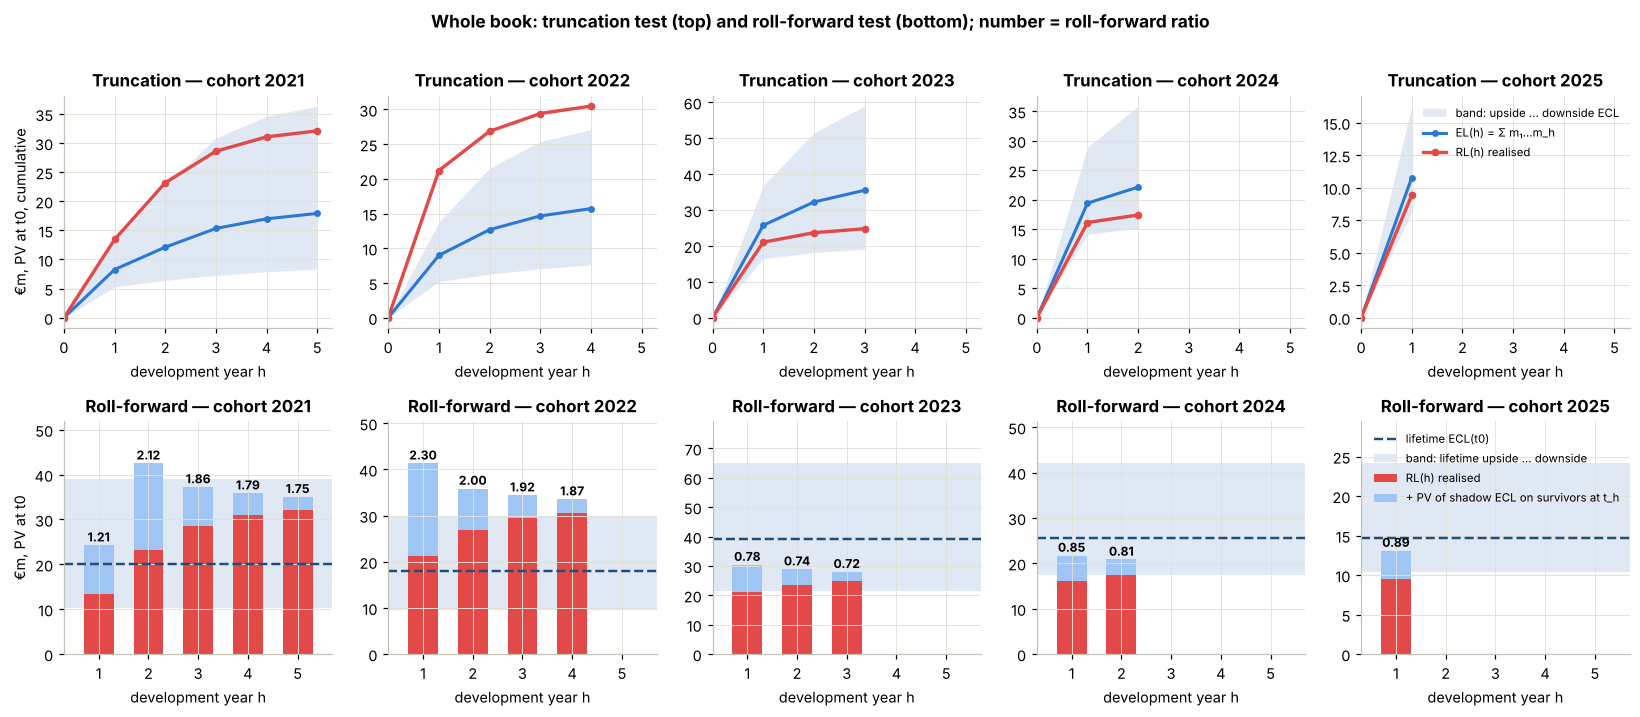

In [14]:
# Side by side: the two survivor treatments
both = (TR[["t0", "population", "h", "ratio"]].rename(columns={"ratio": "truncation_ratio"})
        .merge(RF[["t0", "population", "h", "ratio"]].rename(columns={"ratio": "rollforward_ratio"}), on=["t0", "population", "h"]))
both["difference"] = both.truncation_ratio - both.rollforward_ratio
display(both[both.population == "Whole book (shadow)"].set_index(["t0", "h"]).drop(columns="population").round(3))

fig, axes = plt.subplots(2, 5, figsize=(15, 6.4))
for i, t0 in enumerate(REF_DATES):
    d = TR[(TR.t0 == t0) & (TR.population == "Whole book (shadow)")]; hs = [0] + d.h.tolist(); z = lambda s: [0] + (s / 1e6).tolist()
    ax = axes[0, i]
    ax.fill_between(hs, z(d.EL_upside), z(d.EL_downside), color="#dfe8f3", lw=0, label="band: upside … downside ECL")
    ax.plot(hs, z(d.EL_w), color="#2a78d6", lw=2, marker="o", ms=3.5, label="EL(h) = Σ m₁…m_h")
    ax.plot(hs, z(d.RL), color="#e34948", lw=2.2, marker="o", ms=4, label="RL(h) realised")
    ax.set_title(f"Truncation — cohort {t0}"); ax.set_xticks(range(0, 6)); ax.set_xlim(0, 5.3); ax.set_xlabel("development year h")
    if i == 0: ax.set_ylabel("€m, PV at t0, cumulative")
    if i == 4: ax.legend(fontsize=7.5, loc="upper right")
    r = RF[(RF.t0 == t0) & (RF.population == "Whole book (shadow)")]; ax = axes[1, i]
    ax.bar(r.h, r.RL / 1e6, 0.6, color="#e34948", label="RL(h) realised")
    ax.bar(r.h, r.PV_ECL_survivors / 1e6, 0.6, bottom=r.RL / 1e6, color="#9ec5f4", label="+ PV of shadow ECL on survivors at t_h")
    ax.axhline(r.lifetime_ECL.iloc[0] / 1e6, color="#1f4e79", lw=1.6, ls="--", label="lifetime ECL(t0)")
    ax.axhspan(r.lifetime_up.iloc[0] / 1e6, r.lifetime_down.iloc[0] / 1e6, color="#dfe8f3", lw=0, zorder=0, label="band: lifetime upside … downside")
    top = max(r.RHS.max(), r.lifetime_down.iloc[0]) / 1e6
    for h, v, q in zip(r.h, r.RHS / 1e6, r.ratio): ax.text(h, v + top * 0.02, f"{q:.2f}", ha="center", fontsize=8, fontweight="bold")
    ax.set_ylim(0, top * 1.22); ax.set_title(f"Roll-forward — cohort {t0}"); ax.set_xticks(range(1, 6)); ax.set_xlim(0.3, 5.7); ax.set_xlabel("development year h")
    if i == 0: ax.set_ylabel("€m, PV at t0")
    if i == 4: ax.legend(fontsize=7.5, loc="upper right")
plt.suptitle("Whole book: truncation test (top) and roll-forward test (bottom); number = roll-forward ratio", y=1.01, fontweight="bold")
plt.tight_layout(); plt.show()

For cohort 2021 the roll-forward sits *below* the truncation ratio at *h* = 1 (1.2 vs 1.6): at end-2022 the engine still priced
the survivors on benign scenarios, so part of the under-provision was hidden inside the survivors' ECL. At *h* = 2 the engine's
view swung pessimistic and the roll-forward overshoots; from *h* = 3 the two converge as few survivors remain. That is the
self-referential nature of the roll-forward made visible, and why both are reported.

### B6 — Hindsight ECL (step 7)
The same engine, the same frozen loans, the macro path that actually happened instead of the scenarios. `RL − hindsight` is
what the engine missed even knowing the economy (its fit); `hindsight − booked` is what the scenarios missed. Both tests are
recomputed with the hindsight figures as "expected"; for the roll-forward the survivors' term is then also the hindsight ECL at
*t_h* (engine run at *t_h* with the realised path from there), so that both sides of the test are on the same basis.

In [15]:
HIND = {}
for t0, (c, H) in cohorts.items():
    ur, hpi = macro_path_realised(t0)
    perf = c[c.status == "P"]; comp = model.term_structure(perf, ur, hpi, t0, return_components=True)
    cum = np.zeros((len(c), H5)); life = np.zeros(len(c))
    ip = c.index.get_indexer(perf.index); cum[ip] = comp["m"][:, :H5].cumsum(axis=1); life[ip] = comp["m"].sum(axis=1)
    s3 = c[c.status == "D"]
    if len(s3):
        e3, _ = model.stage3_ecl(s3, ur, hpi, t0); i3 = c.index.get_indexer(s3.index); cum[i3, :] = e3[:, None]; life[i3] = e3
    HIND[t0] = dict(cum=cum, life=life)

# hindsight survivors' term for the roll-forward: the engine run at t_h with the realised path from t_h onward
# (a booked-scenario survivors' term against a hindsight lifetime would mix the two bases)
def survivor_matrix_hind(t0):
    c, H = cohorts[t0]; rl = RL[t0]; defaulted = set(rl.loan_id); S = np.zeros((len(c), H5))
    for h in range(1, H + 1):
        th = snap[(snap.snapshot_year == t0 + h) & snap.loan_id.isin(c.index) & (snap.status == "P")]
        th = th[~th.loan_id.isin(defaulted)].set_index("loan_id")
        ur, hpi = macro_path_realised(t0 + h)
        life_th = model.term_structure(th, ur, hpi, t0 + h).sum(axis=1)
        S[c.index.get_indexer(th.index), h - 1] = life_th * (1 + th.eir.to_numpy()) ** -h
    return S
SURV_HIND = {t0: survivor_matrix_hind(t0) for t0 in REF_DATES}

rows = []
for t0, (c, H) in cohorts.items():
    for pop, f in TESTS.items():
        m = f(c)
        for h in range(1, H + 1):
            rows.append(dict(t0=t0, population=pop, h=h, EL_booked=TS[t0]["cum_w"][m, h - 1].sum(), EL_hind=HIND[t0]["cum"][m, h - 1].sum(),
                             RL=RLM[t0][m, h - 1].sum(), life_booked=c.ecllife_w[m].sum(), life_hind=HIND[t0]["life"][m].sum(),
                             RHS_rf=RLM[t0][m, h - 1].sum() + SURV[t0][m, h - 1].sum(), RHS_rf_hind=RLM[t0][m, h - 1].sum() + SURV_HIND[t0][m, h - 1].sum()))
HD = pd.DataFrame(rows)
HD["trunc_ratio_booked"] = HD.RL / HD.EL_booked; HD["trunc_ratio_hind"] = HD.RL / HD.EL_hind
HD["rf_ratio_booked"] = HD.RHS_rf / HD.life_booked; HD["rf_ratio_hind"] = HD.RHS_rf_hind / HD.life_hind
HD["scenario_miss (hind − booked)"] = HD.EL_hind - HD.EL_booked; HD["engine_miss (RL − hind)"] = HD.RL - HD.EL_hind
HD[HD.population == "Whole book (shadow)"].set_index(["t0", "h"]).drop(columns="population").round(3)

EL_booked        EL_hind             RL    life_booked      life_hind         RHS_rf    RHS_rf_hind  trunc_ratio_booked  trunc_ratio_hind  rf_ratio_booked  \
t0   h                                                                                                                                                                   
2021 1  8,270,137.014  9,030,527.417 13,433,806.115 20,019,313.905 25,879,383.702 24,263,344.594 27,375,489.407               1.624             1.488            1.212   
     2 12,113,361.435 16,430,357.615 23,175,219.667 20,019,313.905 25,879,383.702 42,519,375.862 32,130,716.774               1.913             1.411            2.124   
     3 15,329,427.465 20,816,102.063 28,591,762.464 20,019,313.905 25,879,383.702 37,234,597.281 33,468,569.159               1.865             1.374            1.860   
     4 16,984,650.810 22,776,579.010 31,058,392.143 20,019,313.905 25,879,383.702 35,859,260.138 34,080,854.639               1.829             1.364            1.791   
     5 17,909,098.630 23,724,964.069 32,090,682.181 20,019,313.905 25,879,383.702 35,050,149.987 34,218,071.837               1.792             1.353            1.751   
2022 1  8,984,411.231 13,204,696.681 21,201,036.727 17,947,820.181 23,031,275.246 41,320,589.745 30,520,127.864               2.360             1.606            2.302   
     2 12,679,336.460 17,766,413.636 26,854,896.670 17,947,820.181 23,031,275.246 35,856,434.007 31,935,802.766               2.118             1.512            1.998   
     3 14,664,463.748 19,802,519.972 29,416,327.328 17,947,820.181 23,031,275.246 34,413,226.348 32,563,912.608               2.006             1.485            1.917   
     4 15,713,628.718 20,787,770.889 30,484,070.365 17,947,820.181 23,031,275.246 33,565,153.746 32,699,897.863               1.940             1.466            1.870   
2023 1 25,727,381.798 19,912,000.858 21,021,021.138 39,104,713.481 25,360,761.410 30,428,516.442 26,329,968.980               0.817             1.056            0.778   
     2 32,220,184.310 22,019,202.334 23,673,422.530 39,104,713.481 25,360,761.410 28,900,077.166 26,963,716.358               0.735             1.075            0.739   
     3 35,491,392.958 23,040,201.186 24,777,888.378 39,104,713.481 25,360,761.410 28,000,267.336 27,093,032.780               0.698             1.075            0.716   
2024 1 19,417,559.648 15,622,765.338 16,138,924.234 25,636,283.723 19,193,392.541 21,720,614.696 19,645,099.300               0.831             1.033            0.847   
     2 22,143,161.697 16,717,511.605 17,411,438.752 25,636,283.723 19,193,392.541 20,845,853.080 19,875,231.848               0.786             1.042            0.813   
2025 1 10,781,161.938  8,713,521.357  9,449,518.379 14,726,090.039 11,320,978.299 13,090,500.233 12,058,509.107               0.876             1.084            0.889   

        rf_ratio_hind  scenario_miss (hind − booked)  engine_miss (RL − hind)  
t0   h                                                                         
2021 1          1.058                    760,390.403            4,403,278.698  
     2          1.242                  4,316,996.180            6,744,862.052  
     3          1.293                  5,486,674.598            7,775,660.402  
     4          1.317                  5,791,928.199            8,281,813.133  
     5          1.322                  5,815,865.439            8,365,718.113  
2022 1          1.325                  4,220,285.451            7,996,340.045  
     2          1.387                  5,087,077.176            9,088,483.034  
     3          1.414                  5,138,056.224            9,613,807.356  
     4          1.420                  5,074,142.171            9,696,299.476  
2023 1          1.038                 -5,815,380.940            1,109,020.279  
     2          1.063                -10,200,981.976            1,654,220.196  
     3          1.068                -12,451,191.772            1,737,687.193  
2

### B7 — Every combination: stage at *t₀* × end state at *t_h* (A3 panel D)
Each cohort loan is in exactly one row (its stage at *t₀*) and reaches exactly one column at *t_h*. Per cell: loans, EL under
the truncation test (m₁…m_h), RL, EL under the roll-forward test (full lifetime) and the survivors' term. The only column where
the two tests differ is "still on book". The check at the end confirms that the cells sum to the cohort totals of B4 and B5.

In [16]:
def end_state(t0, h):
    c, H = cohorts[t0]; rl = RL[t0].set_index("loan_id")
    on_book_th = set(snap.loc[(snap.snapshot_year == t0 + h) & (snap.status == "P"), "loan_id"])
    st = pd.Series("left without default", index=c.index)
    st[c.status == "D"] = "Stage 3 open default"
    inw = rl[(rl.stage_t0 < 3) & (rl.tau <= h)]
    st[inw.index] = "defaulted: " + inw.outcome_obs.map({"liquidation": "resolved", "cure": "cured", "unresolved": "unresolved"})
    perf_never = (c.status == "P") & ~c.index.isin(inw.index)
    st[perf_never & c.index.isin(on_book_th)] = "still on book, no default"
    op = rl[rl.stage_t0 == 3]
    st[op.index] = "Stage 3 at t0: " + op.outcome_obs.map({"liquidation": "resolved", "cure": "cured", "unresolved": "unresolved"})
    return st

def matrix_D(t0, h):
    c, H = cohorts[t0]; st = end_state(t0, h)
    df = pd.DataFrame({"stage_t0": c.stage.to_numpy(), "end_state": st.to_numpy(),
                       "EL_truncation": TS[t0]["cum_w"][:, h - 1], "RL": RLM[t0][:, h - 1],
                       "EL_rollforward": c.ecllife_w.to_numpy(), "survivor_term": SURV[t0][:, h - 1]}, index=c.index)
    out = df.groupby(["stage_t0", "end_state"]).agg(loans=("RL", "size"), EL_truncation=("EL_truncation", "sum"), RL=("RL", "sum"),
                                                     EL_rollforward=("EL_rollforward", "sum"), survivor_term=("survivor_term", "sum"))
    out["RL_rollforward"] = out.RL + out.survivor_term
    return out

t0_, h_ = 2021, 3
M = matrix_D(t0_, h_)
display(M.round(0))
tr = TR[(TR.t0 == t0_) & (TR.population == "Whole book (shadow)") & (TR.h == h_)].iloc[0]
rf = RF[(RF.t0 == t0_) & (RF.population == "Whole book (shadow)") & (RF.h == h_)].iloc[0]
print(f"cohort {t0_}, h={h_}:  Σ loans = {M.loans.sum():,} = cohort size {len(cohorts[t0_][0]):,}")
print(f"  truncation:   Σ EL = {EUR(M.EL_truncation.sum())} vs B4 {EUR(tr.EL_w)} | Σ RL = {EUR(M.RL.sum())} vs B4 {EUR(tr.RL)}")
print(f"  roll-forward: Σ EL = {EUR(M.EL_rollforward.sum())} vs B5 {EUR(rf.lifetime_ECL)} | Σ (RL + survivors) = {EUR(M.RL_rollforward.sum())} vs B5 {EUR(rf.RHS)}")
assert np.isclose(M.EL_truncation.sum(), tr.EL_w) and np.isclose(M.RL.sum(), tr.RL) and np.isclose(M.EL_rollforward.sum(), rf.lifetime_ECL) and np.isclose(M.RL_rollforward.sum(), rf.RHS)
print("  survivor term is non-zero only in 'still on book':", bool((M.loc[M.index.get_level_values(1) != 'still on book, no default', 'survivor_term'].abs() < 1e-9).all()))

loans  EL_truncation             RL  EL_rollforward  survivor_term  RL_rollforward
stage_t0 end_state                                                                                                    
1        defaulted: cured             241    290,881.000    540,143.000     415,770.000          0.000     540,143.000
         defaulted: resolved          528    580,490.000 16,493,513.000     828,169.000          0.000  16,493,513.000
         defaulted: unresolved         50     69,228.000  1,554,855.000      98,162.000          0.000   1,554,855.000
         left without default        2599  1,587,724.000          0.000   2,325,514.000          0.000           0.000
         still on book, no default  12048  7,021,253.000          0.000  10,316,851.000  8,219,603.000   8,219,603.000
2        defaulted: cured              22     34,608.000     53,864.000      44,120.000          0.000      53,864.000
         defaulted: resolved           58     96,588.000  1,661,990.000     121,744.000          0.000   1,661,990.000
         defaulted: unresolved          3      6,430.000     53,909.000       8,024.000          0.000      53,909.000
         left without default         153    146,665.000          0.000     186,934.000          0.000           0.000
         still on book, no default    689    604,614.000          0.000     783,079.000    423,232.000     423,232.000
3        Stage 3 at t0: cured          57    757,106.000    122,030.000     757,106.000          0.000     122,030.000
         Stage 3 at t0: resolved      284  4,133,841.000  8,111,458.000   4,133,841.000          0.000   8,111,458.000

cohort 2021, h=3:  Σ loans = 16,732 = cohort size 16,732
  truncation:   Σ EL = €15.33m vs B4 €15.33m | Σ RL = €28.59m vs B4 €28.59m
  roll-forward: Σ EL = €20.02m vs B5 €20.02m | Σ (RL + survivors) = €37.23m vs B5 €37.23m
  survivor term is non-zero only in 'still on book': True


In [17]:
# Default-year attribution of the realised loss, all cohorts × horizons: who defaulted straight from Stage 1 vs from Stage 2/3 at t0
rows = []
for t0, (c, H) in cohorts.items():
    for h in range(1, H + 1):
        st = end_state(t0, h); df = pd.DataFrame({"stage_t0": c.stage.to_numpy(), "RL": RLM[t0][:, h - 1]}, index=c.index)
        g = df.groupby("stage_t0").RL.sum(); rows.append(dict(t0=t0, h=h, **{f"RL_from_stage{k}": g.get(k, 0.0) for k in (1, 2, 3)}, RL_total=g.sum()))
S = pd.DataFrame(rows).set_index(["t0", "h"]); S["share_from_stage1"] = S.RL_from_stage1 / S.RL_total
S.round(3)

RL_from_stage1  RL_from_stage2  RL_from_stage3       RL_total  share_from_stage1
t0   h                                                                                  
2021 1   4,291,195.279     909,122.315   8,233,488.521 13,433,806.115              0.319
     2  13,382,256.502   1,559,474.645   8,233,488.521 23,175,219.667              0.577
     3  18,588,510.981   1,769,762.962   8,233,488.521 28,591,762.464              0.650
     4  20,996,367.354   1,828,536.269   8,233,488.521 31,058,392.143              0.676
     5  22,001,810.856   1,855,382.805   8,233,488.521 32,090,682.181              0.686
2022 1   8,080,328.124   2,028,953.863  11,091,754.739 21,201,036.727              0.381
     2  13,177,125.759   2,586,016.171  11,091,754.739 26,854,896.670              0.491
     3  15,571,873.173   2,752,699.416  11,091,754.739 29,416,327.328              0.529
     4  16,599,422.257   2,792,893.369  11,091,754.739 30,484,070.365              0.545
2023 1   3,218,777.038   2,842,668.171  14,959,575.928 21,021,021.138              0.153
     2   5,156,270.448   3,557,576.153  14,959,575.928 23,673,422.530              0.218
     3   6,038,749.505   3,779,562.945  14,959,575.928 24,777,888.378              0.244
2024 1   2,019,789.888     911,608.194  13,207,526.153 16,138,924.234              0.125
     2   3,102,164.777   1,101,747.822  13,207,526.153 17,411,438.752              0.178
2025 1   1,037,303.480     336,787.766   8,075,427.134  9,449,518.379              0.110

### B8 — Cohort × development-year triangles (step 8)
Rows = *t₀*, columns = *h*, a diagonal = one calendar year. Read rows for the shape of the term structure, columns for stability,
diagonals for macro years. Bias = the same sign along rows and columns on both sides of the 2023 diagonal — and still there
on the hindsight basis.

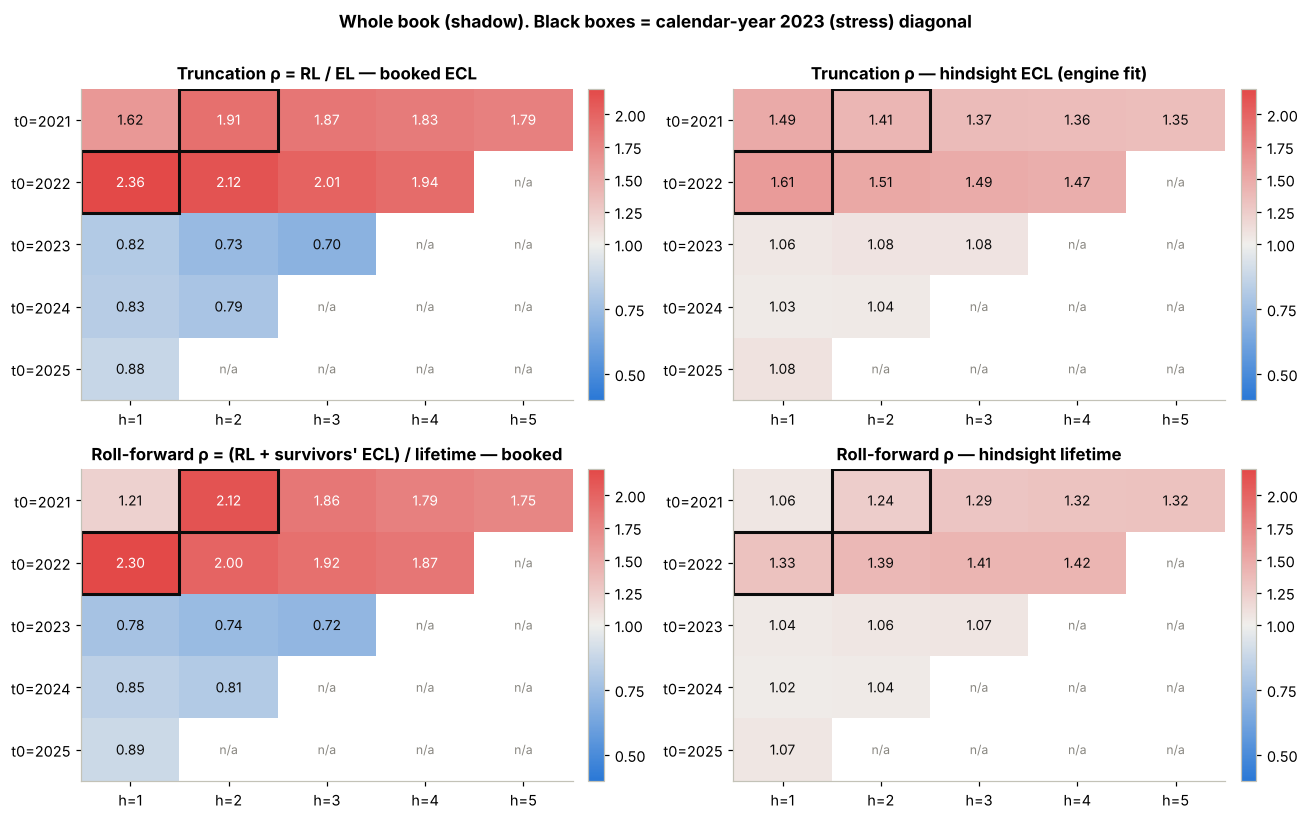

Stage 2+3, truncation ρ (booked):


h,1,2,3,4,5
t0,,,,,
2021,1.690,1.740,1.730,1.720,1.710
2022,2.240,2.210,2.190,2.160,NaN
2023,0.880,0.850,0.830,NaN,NaN
2024,0.860,0.840,NaN,NaN,NaN
2025,0.910,NaN,NaN,NaN,NaN


In [18]:
def tri(df, col, pop="Whole book (shadow)"):
    return df[df.population == pop].pivot(index="t0", columns="h", values=col).reindex(columns=range(1, 6))

def heat(ax, Mx, title, norm, fmt="{:.2f}"):
    A = Mx.to_numpy(dtype=float); im = ax.imshow(A, cmap=DIVERGING, norm=norm, aspect="auto")
    ax.set_xticks(range(5)); ax.set_xticklabels([f"h={h}" for h in range(1, 6)]); ax.set_yticks(range(len(Mx))); ax.set_yticklabels([f"t0={t}" for t in Mx.index]); ax.grid(False)
    for i in range(A.shape[0]):
        for j in range(A.shape[1]):
            if np.isfinite(A[i, j]): ax.text(j, i, fmt.format(A[i, j]), ha="center", va="center", fontsize=9, color="#0b0b0b" if abs(norm(A[i, j]) - .5) < .3 else "#fff")
            else: ax.text(j, i, "n/a", ha="center", va="center", fontsize=8, color="#898781")
            if Mx.index[i] + (j + 1) == 2023: ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False, ec="#0b0b0b", lw=2))
    ax.set_title(title); plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03)

norm = TwoSlopeNorm(vmin=0.4, vcenter=1.0, vmax=2.2)
fig, axes = plt.subplots(2, 2, figsize=(12, 7.4))
heat(axes[0, 0], tri(HD, "trunc_ratio_booked"), "Truncation ρ = RL / EL — booked ECL", norm)
heat(axes[0, 1], tri(HD, "trunc_ratio_hind"), "Truncation ρ — hindsight ECL (engine fit)", norm)
heat(axes[1, 0], tri(HD, "rf_ratio_booked"), "Roll-forward ρ = (RL + survivors' ECL) / lifetime — booked", norm)
heat(axes[1, 1], tri(HD, "rf_ratio_hind"), "Roll-forward ρ — hindsight lifetime", norm)
plt.suptitle("Whole book (shadow). Black boxes = calendar-year 2023 (stress) diagonal", y=1.0, fontweight="bold"); plt.tight_layout(); plt.show()
print("Stage 2+3, truncation ρ (booked):"); display(tri(HD, "trunc_ratio_booked", "Stage 2+3").round(2))

### B9 — Traffic lights on the scenario band (step 9)
No confidence interval exists for one macro path, so adequacy is graded against the range the bank itself declared plausible
at *t₀*: green if the realised figure lies between the upside and the downside ECL, amber if up to 25 % outside or if more than
25 % of RL is still a best estimate on unresolved cases, red beyond. Same rule for both tests.

EL_upside    EL_downside             RL  ratio  unresolved_share status_truncation     reason_truncation    lifetime_up  lifetime_down            RHS  \
t0   h                                                                                                                                                              
2021 1  5,296,725.840 13,237,072.151 13,433,806.115  1.624             0.000             AMBER        above downside 10,179,022.550 38,994,119.969 24,263,344.594   
     2  6,422,556.735 22,627,201.866 23,175,219.667  1.913             0.020             AMBER        above downside 10,179,022.550 38,994,119.969 42,519,375.862   
     3  7,267,973.228 30,884,594.930 28,591,762.464  1.865             0.089             GREEN           inside band 10,179,022.550 38,994,119.969 37,234,597.281   
     4  7,896,353.233 34,582,465.200 31,058,392.143  1.829             0.138             GREEN           inside band 10,179,022.550 38,994,119.969 35,859,260.138   
     5  8,356,252.967 36,342,529.785 32,090,682.181  1.792             0.165             GREEN           inside band 10,179,022.550 38,994,119.969 35,050,149.987   
2022 1  5,226,877.271 13,758,898.017 21,201,036.727  2.360             0.022               RED  above 1.25× downside  9,488,277.492 29,823,777.240 41,320,589.745   
     2  6,284,183.405 21,541,447.601 26,854,896.670  2.118             0.098             AMBER        above downside  9,488,277.492 29,823,777.240 35,856,434.007   
     3  7,060,546.275 25,366,424.127 29,416,327.328  2.006             0.150             AMBER        above downside  9,488,277.492 29,823,777.240 34,413,226.348   
     4  7,625,011.180 27,109,670.874 30,484,070.365  1.940             0.180             AMBER        above downside  9,488,277.492 29,823,777.240 33,565,153.746   
2023 1 16,480,024.744 36,750,455.017 21,021,021.138  0.817             0.130             GREEN           inside band 21,358,831.953 64,926,225.208 30,428,516.442   
     2 18,156,538.879 51,448,806.841 23,673,422.530  0.735             0.194             GREEN           inside band 21,358,831.953 64,926,225.208 28,900,077.166   
     3 19,095,263.193 58,941,931.003 24,777,888.378  0.698             0.230             GREEN           inside band 21,358,831.953 64,926,225.208 28,000,267.336   
2024 1 14,158,260.857 28,891,981.511 16,138,924.234  0.831             0.296             AMBER      unresolved > 25% 17,519,054.049 42,046,472.684 21,720,614.696   
     2 15,145,408.381 35,870,086.727 17,411,438.752  0.786             0.347             AMBER      unresolved > 25% 17,519,054.049 42,046,472.684 20,845,853.080   
2025 1  8,117,219.351 16,275,947.215  9,449,518.379  0.876             0.600             AMBER      unresolved > 25% 10,398,607.339 24,140,734.758 13,090,500.233   

        rf_ratio status_rollforward    reason_rollforward  
t0   h                                                     
2021 1     1.212              GREEN           inside band  
     2     2.124              AMBER        above downside  
     3     1.860              GREEN           inside band  
     4     1.791              GREEN           inside band  
     5     1.751              GREEN           inside band  
2022 1     2.302                RED  above 1.25× downside  
     2     1.998              AMBER        above downside  
     3     1.917              AMBER        above downside  
     4     1.870              AMBER        above downside  
2023 1     0.778              GREEN           inside band  
     2     0.739              GREEN           inside band  
     3     0.716              GREEN           inside band  
2024 1     0.847              AMBER      unresolved > 25%  
     2     0.813              AMBER      unresolved > 25%  
2025 1     0.889              AMBER      unresolved > 25%

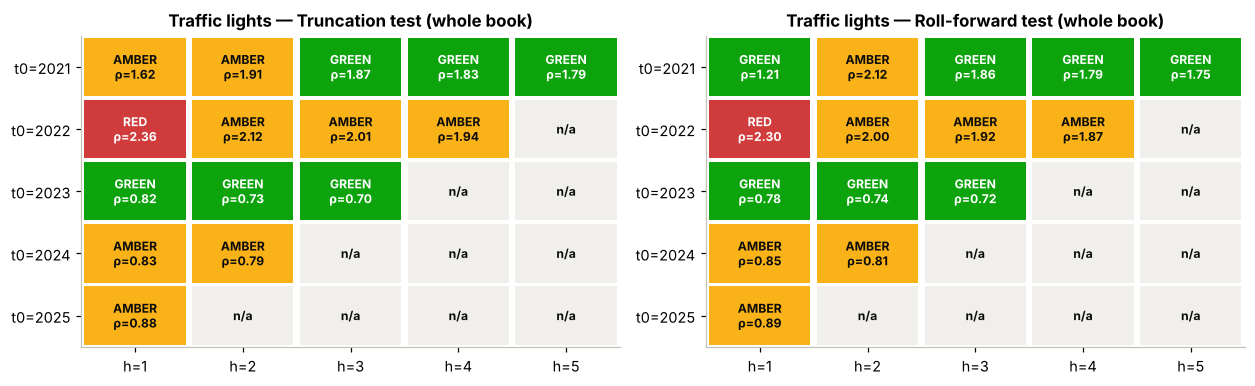

In [19]:
def grade(x, up, down, unres):
    if x > 1.25 * down: return "RED", "above 1.25× downside"
    if x < 0.75 * up:   return "RED", "below 0.75× upside"
    if x > down:        return "AMBER", "above downside"
    if x < up:          return "AMBER", "below upside"
    if unres > 0.25:    return "AMBER", "unresolved > 25%"
    return "GREEN", "inside band"

G = TR[["t0", "population", "h", "EL_upside", "EL_downside", "RL", "ratio", "unresolved_share"]].copy()
G[["status_truncation", "reason_truncation"]] = [grade(r.RL, r.EL_upside, r.EL_downside, r.unresolved_share) for r in G.itertuples()]
r2 = RF[["t0", "population", "h", "lifetime_up", "lifetime_down", "RHS", "ratio"]].rename(columns={"ratio": "rf_ratio"})
G = G.merge(r2, on=["t0", "population", "h"]).merge(TR[["t0", "population", "h", "unresolved_share"]].rename(columns={"unresolved_share": "u"}), on=["t0", "population", "h"])
G[["status_rollforward", "reason_rollforward"]] = [grade(r.RHS, r.lifetime_up, r.lifetime_down, r.u) for r in G.itertuples()]
G = G.drop(columns="u")
display(G[G.population == "Whole book (shadow)"].set_index(["t0", "h"]).drop(columns="population").round(3))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
for ax, (col, rat, title) in zip(axes, [("status_truncation", "ratio", "Truncation test"), ("status_rollforward", "rf_ratio", "Roll-forward test")]):
    gw = G[G.population == "Whole book (shadow)"]
    Mx = gw.pivot(index="t0", columns="h", values=col).reindex(columns=range(1, 6)); Rx = gw.pivot(index="t0", columns="h", values=rat).reindex(columns=range(1, 6))
    ax.set_xlim(-.5, 4.5); ax.set_ylim(4.5, -.5); ax.grid(False)
    for i, t0 in enumerate(Mx.index):
        for j, h in enumerate(Mx.columns):
            s = Mx.loc[t0, h] if isinstance(Mx.loc[t0, h], str) else "n/a"
            ax.add_patch(plt.Rectangle((j - .47, i - .47), .94, .94, color=STATUS_COLORS[s], lw=0))
            ax.text(j, i, f"{s}\nρ={Rx.loc[t0, h]:.2f}" if s != "n/a" else "n/a", ha="center", va="center", fontsize=8, color="#0b0b0b" if s in ("AMBER", "n/a") else "#fff", fontweight="bold")
    ax.set_xticks(range(5)); ax.set_xticklabels([f"h={h}" for h in range(1, 6)]); ax.set_yticks(range(5)); ax.set_yticklabels([f"t0={t}" for t in Mx.index]); ax.set_title(f"Traffic lights — {title} (whole book)")
plt.tight_layout(); plt.show()

### B10 — Paired t-test per cell (step 10; A3 panel E)
For every loan *i* of the cohort, *dᵢ* = realised − expected to *h*; *t* = mean(d) / [sd(d)/√n]. Σdᵢ is the cell's gap, so the
test is the gap divided by its loan-level standard error.

* **Truncation:** dᵢ = RLᵢ(h) − Σ_{k≤h} m_{i,k}.
* **Roll-forward:** dᵢ = RLᵢ(h) + survivor termᵢ(h) − lifetime ECLᵢ (on the hindsight basis both the lifetime and the survivor term are hindsight figures).

On the **hindsight** basis (expected = hindsight ECL) the macro path is held fixed, the loan-level differences are independent,
and *t* is a valid test of whether the engine is biased for these loans. On the **booked** basis every loan shares the one macro
surprise, which the standard error ignores, so |t| is inflated in stress years — indicative only; booked adequacy is graded by the
band (B9). The 15 cell ratios must not be t-tested against 1: they overlap in loans and calendar years.

Whole book (shadow): t per cell. Gap in €, SE of the gap in €


n  gap_trunc_booked  se_trunc_booked  t_trunc_booked  t_trunc_hind  p_trunc_hind  t_rf_booked  t_rf_hind  p_rf_hind
t0   h                                                                                                                         
2021 1  16732     5,163,669.101      736,032.469           7.016         6.056         0.000        5.821      2.075      0.038
     2  16732    11,061,858.232    1,001,334.064          11.047         6.796         0.000       22.825      6.409      0.000
     3  16732    13,262,335.000    1,083,750.083          12.237         7.252         0.000       16.158      7.165      0.000
     4  16732    14,073,741.333    1,111,207.717          12.665         7.537         0.000       14.410      7.519      0.000
     5  16732    14,181,583.552    1,114,344.661          12.726         7.590         0.000       13.581      7.603      0.000
2022 1  15554    12,216,625.496      898,041.449          13.604         9.356         0.000       26.357      8.910      0.000
     2  15554    14,175,560.210      998,924.228          14.191         9.492         0.000       18.270      9.429      0.000
     3  15554    14,751,863.580    1,031,652.602          14.299         9.700         0.000       16.154      9.700      0.000
     4  15554    14,770,441.647    1,035,703.463          14.261         9.740         0.000       15.193      9.768      0.000
2023 1  14477    -4,706,360.661      653,082.608          -7.206         1.713         0.087      -13.625      1.522      0.128
     2  14477    -8,546,761.781      710,048.413         -12.037         2.351         0.019      -14.611      2.303      0.021
     3  14477   -10,713,504.579      722,084.040         -14.837         2.440         0.015      -15.542      2.450      0.014
2024 1  13506    -3,278,635.414      436,966.208          -7.503         1.215         0.224       -9.123      1.076      0.282
     2  13506    -4,731,722.945      457,638.437         -10.339         1.560         0.119      -10.609      1.547      0.122
2025 1  12508    -1,331,643.559      213,956.766          -6.224         3.464         0.001       -7.779      3.520      0.000

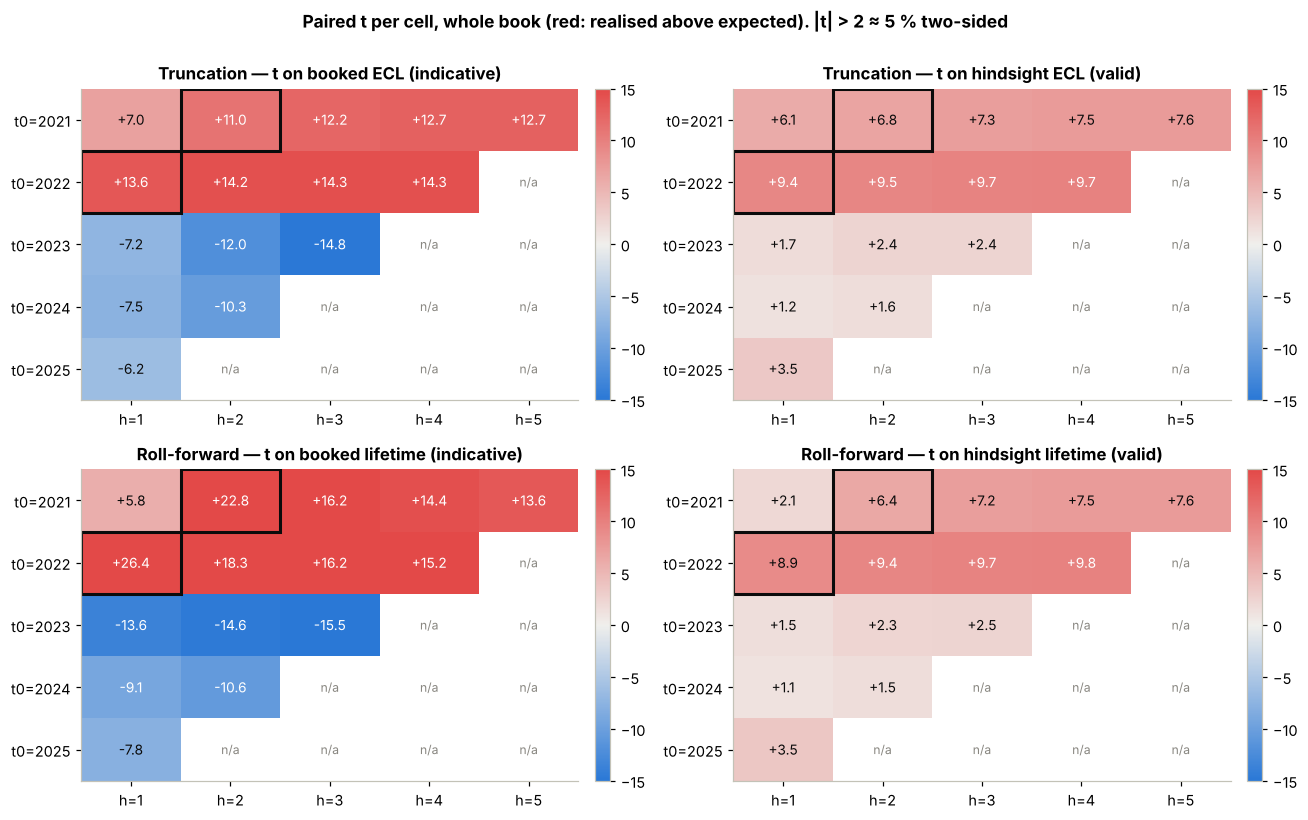

Stage 2+3 — t on hindsight ECL, truncation:


h,1,2,3,4,5
t0,,,,,
2021,6.000,6.300,6.200,6.200,6.100
2022,9.700,9.800,9.800,9.800,NaN
2023,1.500,1.900,1.900,NaN,NaN
2024,0.300,0.300,NaN,NaN,NaN
2025,3.400,NaN,NaN,NaN,NaN


In [20]:
def paired_t(t0, pop, h):
    c, H = cohorts[t0]; m = TESTS[pop](c)
    rl = RLM[t0][m, h - 1]; sv = SURV[t0][m, h - 1]
    out = dict(t0=t0, population=pop, h=h, n=int(m.sum()))
    svh = SURV_HIND[t0][m, h - 1]
    for name, d in [("trunc_booked", rl - TS[t0]["cum_w"][m, h - 1]), ("trunc_hind", rl - HIND[t0]["cum"][m, h - 1]),
                    ("rf_booked", rl + sv - c.ecllife_w.to_numpy()[m]), ("rf_hind", rl + svh - HIND[t0]["life"][m])]:
        se = d.std(ddof=1) / np.sqrt(len(d)); out[f"t_{name}"] = d.mean() / se; out[f"gap_{name}"] = d.sum(); out[f"se_{name}"] = se * len(d)
    return out

TT = pd.DataFrame([paired_t(t0, p, h) for t0, (c, H) in cohorts.items() for p in TESTS for h in range(1, H + 1)])
TT["p_trunc_hind"] = 2 * stats.t.sf(TT.t_trunc_hind.abs(), TT.n - 1); TT["p_rf_hind"] = 2 * stats.t.sf(TT.t_rf_hind.abs(), TT.n - 1)
print("Whole book (shadow): t per cell. Gap in €, SE of the gap in €")
display(TT[TT.population == "Whole book (shadow)"].set_index(["t0", "h"])[["n", "gap_trunc_booked", "se_trunc_booked", "t_trunc_booked", "t_trunc_hind", "p_trunc_hind", "t_rf_booked", "t_rf_hind", "p_rf_hind"]].round(3))

fig, axes = plt.subplots(2, 2, figsize=(12, 7.4)); tn = TwoSlopeNorm(vmin=-15, vcenter=0, vmax=15)
heat(axes[0, 0], tri(TT, "t_trunc_booked"), "Truncation — t on booked ECL (indicative)", tn, "{:+.1f}")
heat(axes[0, 1], tri(TT, "t_trunc_hind"), "Truncation — t on hindsight ECL (valid)", tn, "{:+.1f}")
heat(axes[1, 0], tri(TT, "t_rf_booked"), "Roll-forward — t on booked lifetime (indicative)", tn, "{:+.1f}")
heat(axes[1, 1], tri(TT, "t_rf_hind"), "Roll-forward — t on hindsight lifetime (valid)", tn, "{:+.1f}")
plt.suptitle("Paired t per cell, whole book (red: realised above expected). |t| > 2 ≈ 5 % two-sided", y=1.0, fontweight="bold"); plt.tight_layout(); plt.show()
print("Stage 2+3 — t on hindsight ECL, truncation:"); display(tri(TT, "t_trunc_hind", "Stage 2+3").round(1))

### B11 — Data checks (step 11)

In [21]:
ev2 = events[(events.default_year >= 2022) & events.stage_prev_snapshot.notna()]
st = snap[snap.snapshot_year < LAST].groupby(["snapshot_year", "stage"]).size().rename("exposures").reset_index(); st["year"] = st.snapshot_year + 1
dr = ev2.groupby(["default_year", "stage_prev_snapshot"]).size().rename("defaults").reset_index().rename(columns={"default_year": "year", "stage_prev_snapshot": "stage"})
dd = st.merge(dr, on=["year", "stage"], how="left").fillna({"defaults": 0}); dd["default_rate"] = dd.defaults / dd.exposures
print("Default rate by prior-snapshot stage (should move with the macro, not jump):"); display(dd[dd.stage < 3].pivot(index="year", columns="stage", values="default_rate").round(4))
checks = {"default definition changed in window": False, "re-defaults after cure (loans with > 1 event)": int((events.groupby("loan_id").size() > 1).sum()),
          "events unresolved at 31 Dec 2026": int((~events.resolved_by_last_obs & (events.default_year <= LAST)).sum()),
          "sold / securitised exposures": 0, "forborne exposures": 0, "engine recalibrated within window": False}
for k, v in checks.items(): print(f"  {k:48s}: {v}")
print("\nUnresolved share of RL per cell (whole book) — cells > 25 % are provisional:"); display(tri(TR, "unresolved_share").round(2))

Default rate by prior-snapshot stage (should move with the macro, not jump):


stage,1,2
year,,
2022,0.009,0.031
2023,0.023,0.090
2024,0.016,0.063
2025,0.011,0.045
2026,0.008,0.029


  default definition changed in window            : False
  re-defaults after cure (loans with > 1 event)   : 69
  events unresolved at 31 Dec 2026                : 293
  sold / securitised exposures                    : 0
  forborne exposures                              : 0
  engine recalibrated within window               : False

Unresolved share of RL per cell (whole book) — cells > 25 % are provisional:


h,1,2,3,4,5
t0,,,,,
2021,0.000,0.020,0.090,0.140,0.170
2022,0.020,0.100,0.150,0.180,NaN
2023,0.130,0.190,0.230,NaN,NaN
2024,0.300,0.350,NaN,NaN,NaN
2025,0.600,NaN,NaN,NaN,NaN


### B12 — Verification against the planted truth
At ECL level the backtest should (i) reject "no bias" on the hindsight basis for the cohorts whose horizon includes the
house-price fall, with realised above expected; (ii) show the booked-basis sign flip at the 2023 diagonal as a scenario effect,
not an engine effect; (iii) show the roll-forward at *h* = 1 for the 2021 cohort below the truncation ratio (the engine's
optimistic view of survivors). It is not expected to say which component is wrong — that is outside a top-down test.

In [22]:
wb = TT[TT.population == "Whole book (shadow)"].set_index(["t0", "h"])
pre = wb.loc[[2021, 2022]]; post = wb.loc[[2023, 2024, 2025]]
i_bias = bool((pre.t_trunc_hind > 2).all() and (pre.t_rf_hind > 2).all())
hd = HD[HD.population == "Whole book (shadow)"].set_index(["t0", "h"])
ii_flip = bool((hd.loc[[2021, 2022], "trunc_ratio_booked"] > 1).all() and (hd.loc[[2023, 2024, 2025], "trunc_ratio_booked"] < 1).all()
               and (hd.loc[[2023, 2024, 2025], "trunc_ratio_hind"].between(0.9, 1.2)).all())
b21 = both[(both.t0 == 2021) & (both.population == "Whole book (shadow)")].set_index("h")
iii_rf = bool(b21.loc[1, "rollforward_ratio"] < b21.loc[1, "truncation_ratio"] - 0.2 and abs(b21.loc[5, "rollforward_ratio"] - b21.loc[5, "truncation_ratio"]) < 0.1)

print(f"(i)   Engine bias on the hindsight basis, cohorts 2021–22, all horizons, both tests: {'DETECTED' if i_bias else 'NOT detected'}"
      f"  | t range truncation {pre.t_trunc_hind.min():+.1f} … {pre.t_trunc_hind.max():+.1f}, roll-forward {pre.t_rf_hind.min():+.1f} … {pre.t_rf_hind.max():+.1f}")
print(f"      Post-stress cohorts on the hindsight basis: t {post.t_trunc_hind.min():+.1f} … {post.t_trunc_hind.max():+.1f} — weak, consistent with an error that bites when prices fall")
print(f"(ii)  Booked ratios > 1 before the 2023 diagonal and < 1 after it, hindsight ratios ≈ 1 after it (scenario miss, not engine): {'YES' if ii_flip else 'NO'}")
print(f"(iii) Cohort 2021: roll-forward {b21.loc[1,'rollforward_ratio']:.2f} vs truncation {b21.loc[1,'truncation_ratio']:.2f} at h=1, converging to "
      f"{b21.loc[5,'rollforward_ratio']:.2f} vs {b21.loc[5,'truncation_ratio']:.2f} at h=5: {'YES' if iii_rf else 'NO'}")
assert i_bias and ii_flip and iii_rf, "Backtest did not reproduce the expected ECL-level signature"

(i)   Engine bias on the hindsight basis, cohorts 2021–22, all horizons, both tests: DETECTED  | t range truncation +6.1 … +9.7, roll-forward +2.1 … +9.8
      Post-stress cohorts on the hindsight basis: t +1.2 … +3.5 — weak, consistent with an error that bites when prices fall
(ii)  Booked ratios > 1 before the 2023 diagonal and < 1 after it, hindsight ratios ≈ 1 after it (scenario miss, not engine): YES
(iii) Cohort 2021: roll-forward 1.21 vs truncation 1.62 at h=1, converging to 1.75 vs 1.79 at h=5: YES


## B13 — Summary for the Model Risk Committee

In [23]:
tw = TR[TR.population == "Whole book (shadow)"].set_index(["t0", "h"]); rw = RF[RF.population == "Whole book (shadow)"].set_index(["t0", "h"])
gw = G[G.population == "Whole book (shadow)"]; n_red = (gw.status_truncation == "RED").sum(); n_amb = (gw.status_truncation == "AMBER").sum(); n_grn = (gw.status_truncation == "GREEN").sum()
print(textwrap.dedent(f'''
TOP-DOWN IFRS 9 ECL BACKTEST — RESIDENTIAL MORTGAGES — RUN AS AT 31 DEC 2026
Cohorts 31 Dec 2021 … 2025, development years 1–5, {len(loans):,} loans. Realised loss = default-event economic loss discounted to t0;
write-offs not used. Whole book tested with the shadow lifetime ECL for Stage 1; Stage 2+3 tested on booked figures.

1. ADEQUACY (truncation test, booked ECL, scenario band). Pre-stress cohorts were under-provided: cohort 2021 realised
   {tw.loc[(2021,1),'ratio']:.2f}× the expected loss after one year and {tw.loc[(2021,5),'ratio']:.2f}× after five (gap {EUR(tw.loc[(2021,5),'gap'])}); cohort 2022
   {tw.loc[(2022,1),'ratio']:.2f}× at h=1. Post-stress cohorts (2023–25), set with pessimistic scenarios, run at {tw.loc[[2023,2024,2025]].ratio.min():.2f}–{tw.loc[[2023,2024,2025]].ratio.max():.2f}×.
   Traffic lights: {n_red} red, {n_amb} amber, {n_grn} green of {len(gw)} whole-book cells; red and amber sit on and before the 2023 diagonal, plus
   recent cells that are provisional (unresolved share > 25 %).

2. SURVIVORS. The roll-forward test (lifetime ECL vs realised + ECL still held on survivors) tells the same story from h=2 on;
   at h=1 for cohort 2021 it reads {rw.loc[(2021,1),'ratio']:.2f}× against {tw.loc[(2021,1),'ratio']:.2f}× for the truncation test, because at end-2022 the engine still
   priced the survivors on benign scenarios. The two converge by h=3 ({rw.loc[(2021,3),'ratio']:.2f}× vs {tw.loc[(2021,3),'ratio']:.2f}×).

3. SCENARIOS OR ENGINE. With the realised macro path fed to the same engine (hindsight), cohorts 2021–22 still show
   {hd.loc[(2021,5),'trunc_ratio_hind']:.2f}× and {hd.loc[(2022,4),'trunc_ratio_hind']:.2f}×, while 2023–25 fall to {hd.loc[[2023,2024,2025],'trunc_ratio_hind'].min():.2f}–{hd.loc[[2023,2024,2025],'trunc_ratio_hind'].max():.2f}×. The booked-basis swing from > 1 to < 1
   across the 2023 diagonal is the scenario set; the residual above 1 on the hindsight basis is the engine.

4. FIT (paired t-test). On the hindsight basis the engine is biased low beyond chance for the 2021–22 cohorts at every
   horizon and under both tests (t = {pre.t_trunc_hind.min():+.1f} to {pre.t_trunc_hind.max():+.1f}); for 2023–25 the evidence is weak (t = {post.t_trunc_hind.min():+.1f} to {post.t_trunc_hind.max():+.1f}).
   Same sign on both sides of the stress diagonal, still present with the economy known = systematic bias, confirmed.
   The booked-basis t values (up to {wb.t_trunc_booked.abs().max():+.1f}) are not evidence about the engine: all loans share one macro surprise.

5. CONCLUSION. The provision was inadequate for the loans held before the 2023 price fall and the shortfall is not explained
   by the scenarios alone: the ECL engine under-forecasts losses in a falling market. Which component drives it (PD, LGD,
   staging) is for the component validations; this test says the engine is biased, by how much and when.

6. LIMITS. One macro history; cells with unresolved share > 25 % are provisional; the best-estimate treatment of unresolved
   cases re-imports the Stage 3 provision; no sales, forbearance or default-definition change in the window.
'''))


TOP-DOWN IFRS 9 ECL BACKTEST — RESIDENTIAL MORTGAGES — RUN AS AT 31 DEC 2026
Cohorts 31 Dec 2021 … 2025, development years 1–5, 20,000 loans. Realised loss = default-event economic loss discounted to t0;
write-offs not used. Whole book tested with the shadow lifetime ECL for Stage 1; Stage 2+3 tested on booked figures.

1. ADEQUACY (truncation test, booked ECL, scenario band). Pre-stress cohorts were under-provided: cohort 2021 realised
   1.62× the expected loss after one year and 1.79× after five (gap €14.18m); cohort 2022
   2.36× at h=1. Post-stress cohorts (2023–25), set with pessimistic scenarios, run at 0.70–0.88×.
   Traffic lights: 1 red, 8 amber, 6 green of 15 whole-book cells; red and amber sit on and before the 2023 diagonal, plus
   recent cells that are provisional (unresolved share > 25 %).

2. SURVIVORS. The roll-forward test (lifetime ECL vs realised + ECL still held on survivors) tells the same story from h=2 on;
   at h=1 for cohort 2021 it reads 1.21× against 1.62×